In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import tqdm as tqdm


In [2]:
SM_data_all = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_7-10-2024.txt')
#import missing data files
cmi_data = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_CMI.csv')
mon_data = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_MON.csv')
siu_data = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_SIU.csv')
#set station ID to be one ID, currently has two one with and one without spaces
cmi_data['Station']= 'cmi'
mon_data['Station'] = 'mon'
siu_data['Station'] = 'siu'

#change column names to match, have 'Precip' and 'preciptation'
cmi_data['Precipitation (in)'] = cmi_data['Precip (in)']
mon_data['Precipitation (in)'] = mon_data['Precip (in)']
siu_data['Precipitation (in)'] = siu_data['Precip (in)']

cmi_data['Date & Time (CST)'] = pd.to_datetime(cmi_data['Date & Time (CST)'])
mon_data['Date & Time (CST)'] = pd.to_datetime(mon_data['Date & Time (CST)'])
siu_data['Date & Time (CST)'] = pd.to_datetime(siu_data['Date & Time (CST)'])
SM_data_all['Date & Time (CST)'] = pd.to_datetime(SM_data_all['Date & Time (CST)'].str[:19])
#concatenate all data
SM_data_all = pd.concat([SM_data_all, cmi_data, mon_data, siu_data], axis = 0)
SM_data_all = SM_data_all.reset_index(drop = True)
SM_data_all = SM_data_all.drop('Precip (in)', axis = 1)
#drop 2008 data because they switched from bucket weight units to inches per hour, data complete mess.
SM_data_all['Year'] = SM_data_all['Date & Time (CST)'].dt.year
SM_data_all = SM_data_all[SM_data_all['Year'] != 2008]
SM_data_all = SM_data_all.drop('Year', axis = 1)

What is wfv?
water fraction volume cm3/cm3 volumetric fraction of soil column that is water (relative to total 
absolut volume)

In [3]:
SM_data_all.Station.unique()


array(['bbc', 'brw', 'bvl', 'dek', 'dxs', 'fai', 'fre', 'frm', 'icc',
       'llc', 'oln', 'orr', 'rnd', 'sfm', 'sni', 'stc', 'ste', 'cmi',
       'mon', 'siu'], dtype=object)

In [4]:
SM_data_all

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv)
0,bbc,2010-07-16 12:00:00,0.0,0.237,0.270,0.154,0.167,0.164,0.077
1,bbc,2010-07-16 13:00:00,0.0,0.236,0.266,0.152,0.168,0.164,0.077
2,bbc,2010-07-16 14:00:00,0.0,0.235,0.266,0.152,0.167,0.162,0.079
3,bbc,2010-07-16 15:00:00,0.0,0.234,0.265,0.152,0.166,0.163,0.078
4,bbc,2010-07-16 16:00:00,0.0,0.233,0.265,0.152,0.168,0.163,0.077
...,...,...,...,...,...,...,...,...,...
2714121,siu,2023-12-31 20:00:00,0.0,0.317,0.362,0.322,0.298,0.298,0.461
2714122,siu,2023-12-31 21:00:00,0.0,0.318,0.362,0.323,0.299,0.297,0.461
2714123,siu,2023-12-31 22:00:00,0.0,0.317,0.361,0.323,0.300,0.295,0.461
2714124,siu,2023-12-31 23:00:00,0.0,0.317,0.361,0.323,0.298,0.296,0.461


# Data is not in order and soil moisture values =<0 and >0.7 need to be removed, replace with NaN

we are assuming no data means there is no rain since we cannot measure ammount and precipitation and
we are only concerned with the peak values and difference and can assume cutting some events short 
or not including them has low impact on the peak values and changes

## remove rain that is over 3 in/hr rate, these are unlikely to be true for Illinois and only occur a handful of times in the entire datasets
## set unprobable threshold to remove for isolate rainrates, ie if precip is over 2 in/hr but there is no precip for timestep before and after it is unlikely to be a real measurement 

In [5]:
#clean data, remove impossible values
def clean_data(data,precip_cutoff, sm_cutoff, unlikely_threshold):
    Data_column_names = ['Soil Moisture 5cm (wfv)', 'Soil Moisture 10cm (wfv)', 
                     'Soil Moisture 20cm (wfv)','Soil Moisture 50cm (wfv)', 
                     'Soil Moisture 100cm (wfv)', 'Soil Moisture 150cm (wfv)']
    for i in range(len(Data_column_names)):
        data.loc[data[Data_column_names[i]] <= 0, Data_column_names[i]] = np.NaN 
        data.loc[data[Data_column_names[i]] >sm_cutoff, Data_column_names[i]] = np.NaN

    data.loc[data['Precipitation (in)'] > precip_cutoff, 'Precipitation (in)'] =np.NaN
    data['Precipitation_diff'] = np.NaN
    data['Precipitation_downshift'] = np.NaN
    data['Precipitation_upshift'] = np.NaN
    
    #station's data are not linear, but scrabmled, put in order
    Stations = data.Station.unique()
    for s in Stations:
        station_data = data.loc[data['Station'] == s]

        station_data = station_data.sort_values(by = 'Date & Time (CST)')
        station_data = station_data.reset_index(drop = True)

        station_data['Precipitation_diff'] = station_data['Precipitation (in)'].diff()
        station_data['Precipitation_downshift'] = station_data['Precipitation (in)'].shift(1)
        station_data[ 'Precipitation_upshift'] = station_data['Precipitation (in)'].shift(-1)

        if s == 'bbc':
            new_df = station_data
        else:
            new_df = pd.concat([new_df, station_data], axis = 0)

    new_df = new_df.reset_index(drop = True)
    new_df.loc[(new_df['Precipitation_diff'] >= unlikely_threshold) &  
                                 (new_df['Precipitation_upshift'] == 0), 
                                 'Precipitation (in)' ] = np.NaN
    return new_df

sm_max_threshold = 0.7
precip_rate_max_threshold = 3
unlikely_isolated_precip = 2
SM_data_cleaned = clean_data(SM_data_all, precip_cutoff=precip_rate_max_threshold, 
                                          sm_cutoff= sm_max_threshold, 
                                          unlikely_threshold= unlikely_isolated_precip)

In [6]:
SM_data_cleaned.head()

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift
0,bbc,2009-01-01 00:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.08,NaN,NaN,0.0
1,bbc,2009-01-01 01:00:00,0.0,0.27,0.28,0.2,0.22,0.18,0.08,0.0,0.0,0.0
2,bbc,2009-01-01 02:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0
3,bbc,2009-01-01 03:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0
4,bbc,2009-01-01 04:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0


In [7]:
# locate the areas where the change in precipitation is greater than 2 inches and sandwhiched between 0s
sus_precip = SM_data_cleaned.loc[(SM_data_cleaned['Precipitation_diff'] >= 2) &  
                                 (SM_data_cleaned['Precipitation_upshift'] == 0) ]

sus_precip

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift
192648,brw,2014-05-20 14:00:00,NaN,0.374,0.379,0.364,0.421,0.575,0.511,2.844,0.000,0.0
547662,dxs,2009-10-08 20:00:00,NaN,0.490,0.450,0.430,0.470,0.490,0.490,2.066,0.049,0.0
832569,fre,2012-04-18 12:00:00,NaN,0.342,0.315,0.382,0.353,0.429,0.422,2.928,0.000,0.0
2190783,cmi,2011-03-02 16:00:00,NaN,0.300,0.440,0.410,0.400,0.370,0.380,2.533,0.000,0.0
2291936,cmi,2022-09-19 01:00:00,NaN,0.400,0.200,0.410,0.350,0.370,0.310,2.061,0.000,0.0


max of precip values 2.48
min of sm values 0.002
max of sm values 0.684


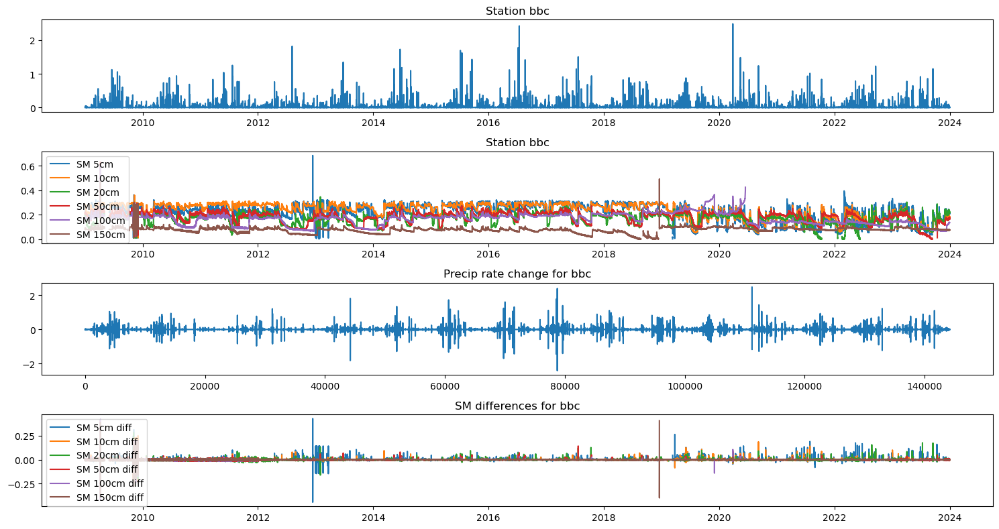

max of precip values 2.514
min of sm values 0.08
max of sm values 0.7


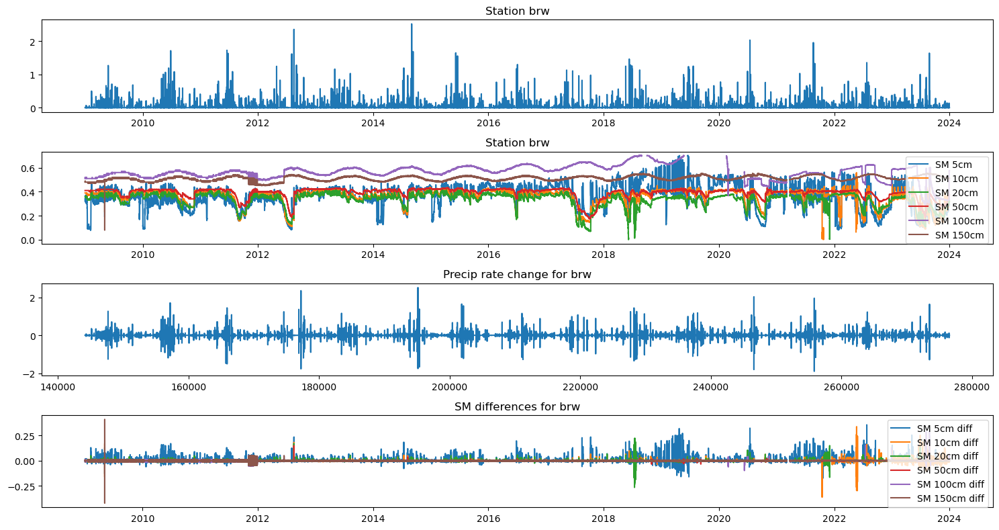

max of precip values 2.307
min of sm values 0.034
max of sm values 0.552


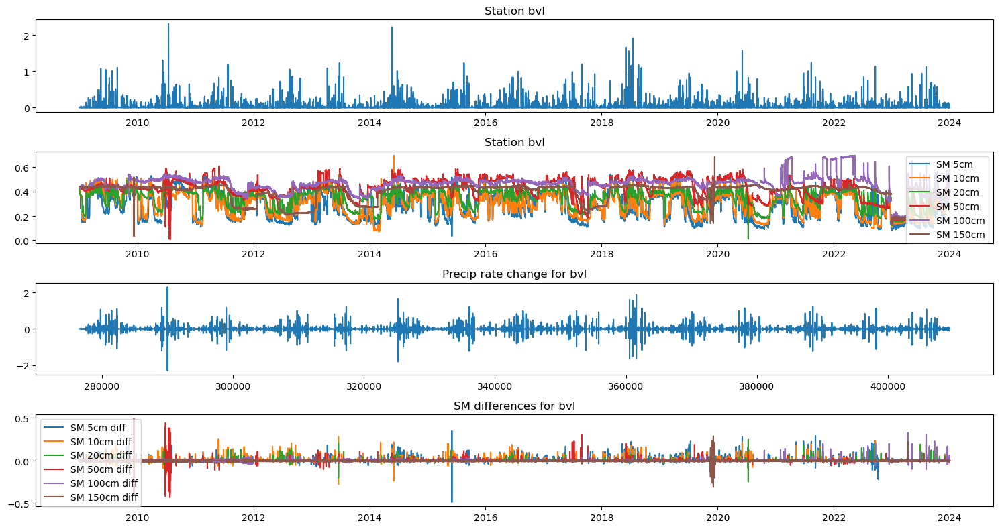

max of precip values 2.403
min of sm values 0.042
max of sm values 0.55


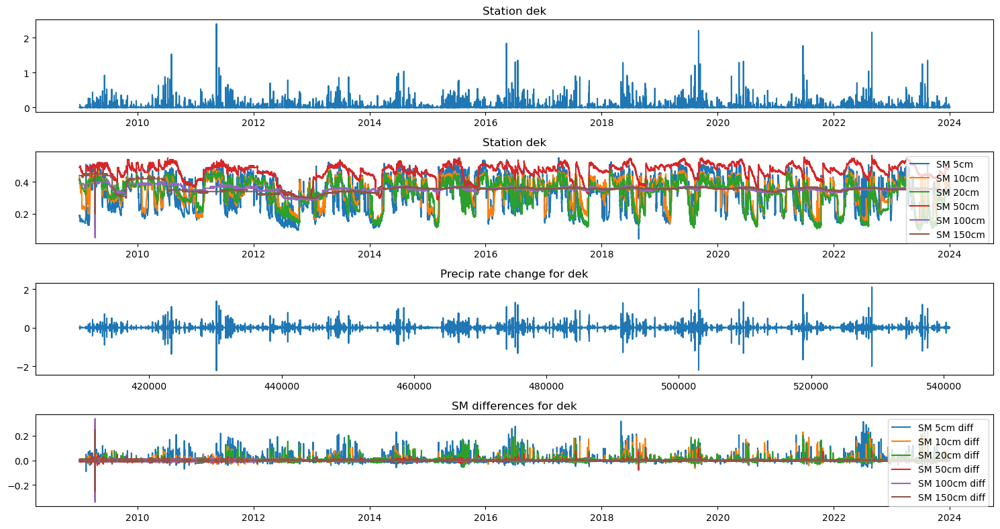

max of precip values 2.818
min of sm values 0.021
max of sm values 0.7


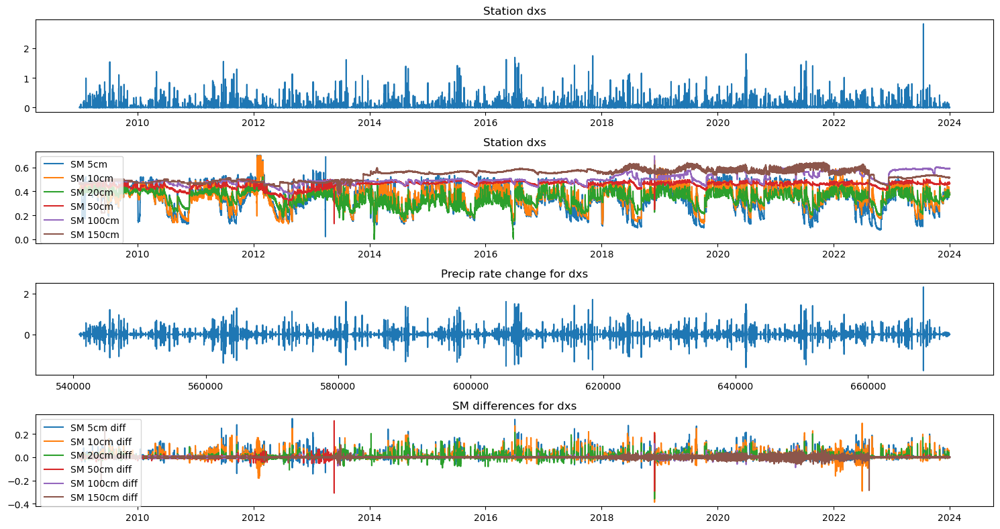

max of precip values 2.379
min of sm values 0.15
max of sm values 0.622


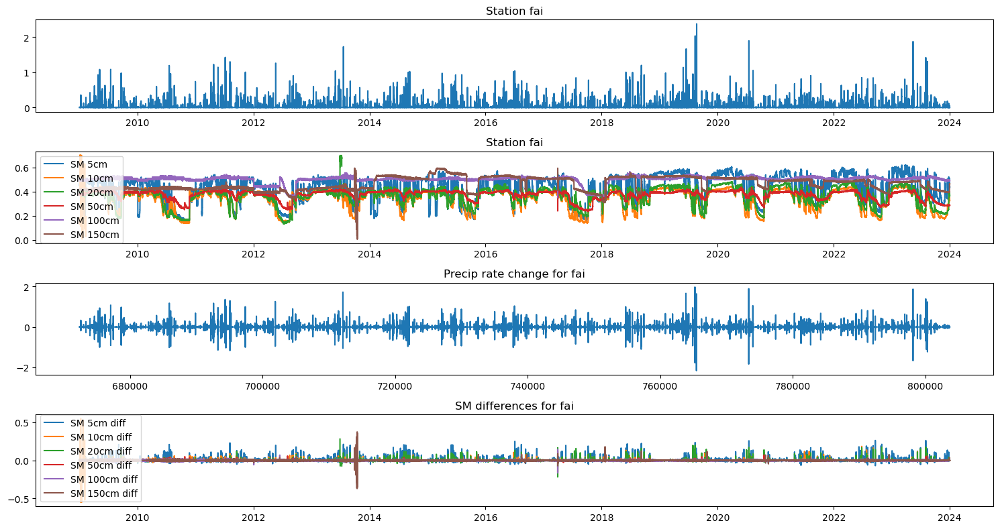

max of precip values 2.831
min of sm values 0.026
max of sm values 0.61


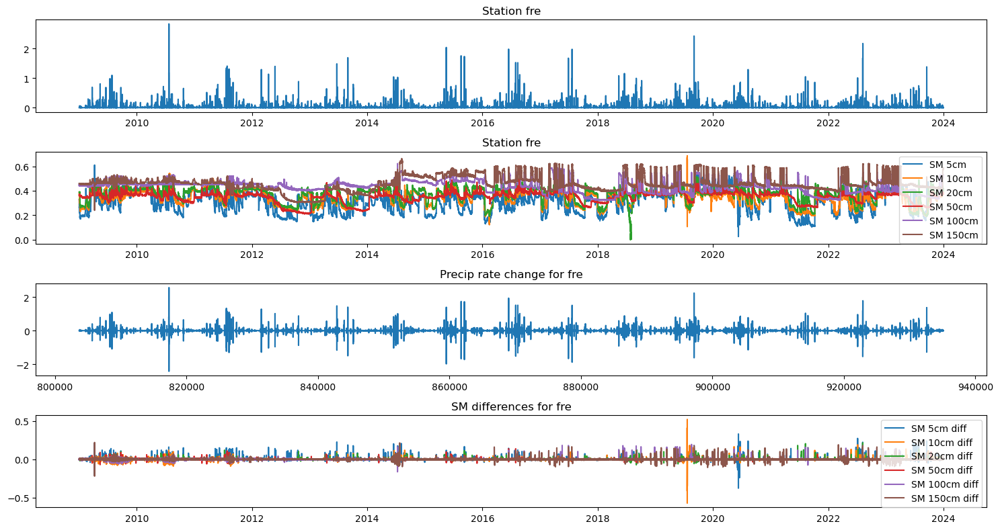

max of precip values 2.361
min of sm values 0.002
max of sm values 0.7


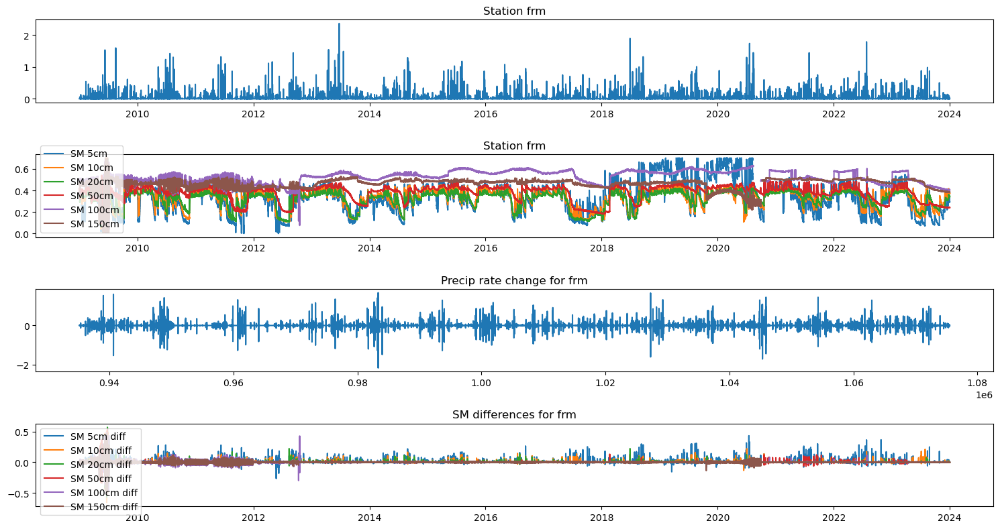

max of precip values 2.384
min of sm values 0.084
max of sm values 0.505


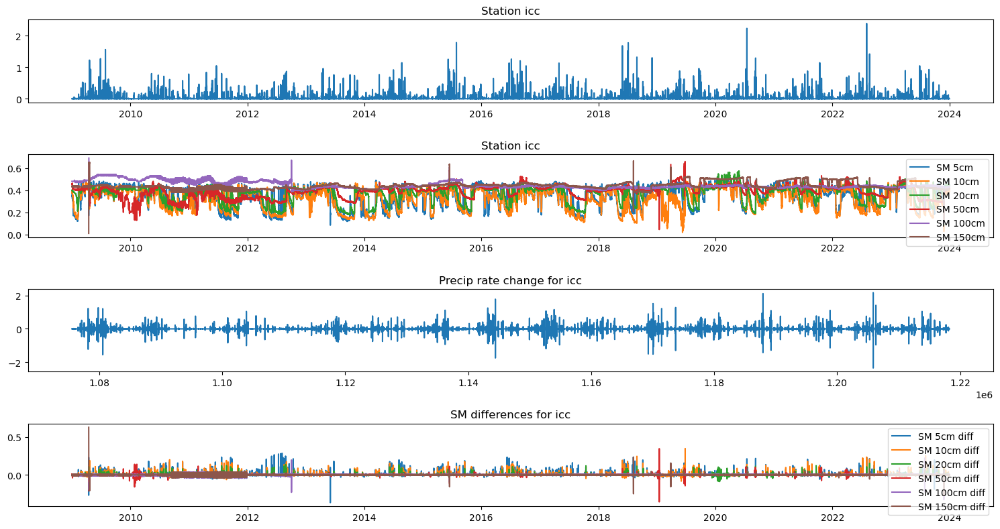

max of precip values 1.945
min of sm values 0.029
max of sm values 0.535


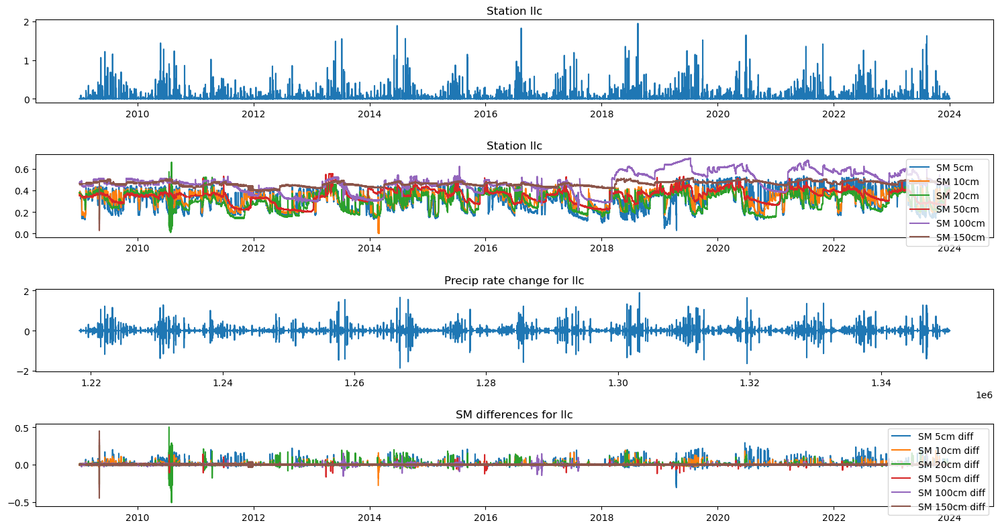

max of precip values 2.417
min of sm values 0.028
max of sm values 0.699


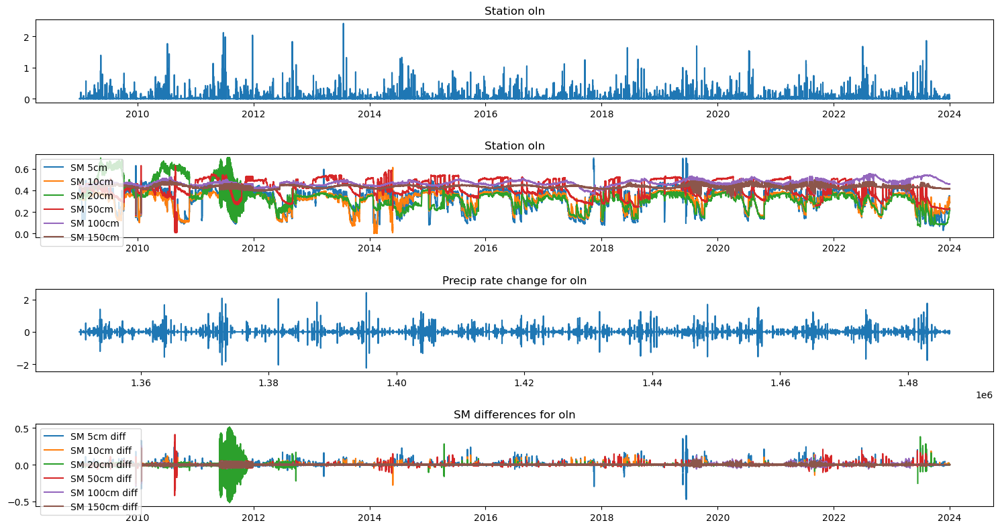

max of precip values 2.381
min of sm values 0.12
max of sm values 0.591


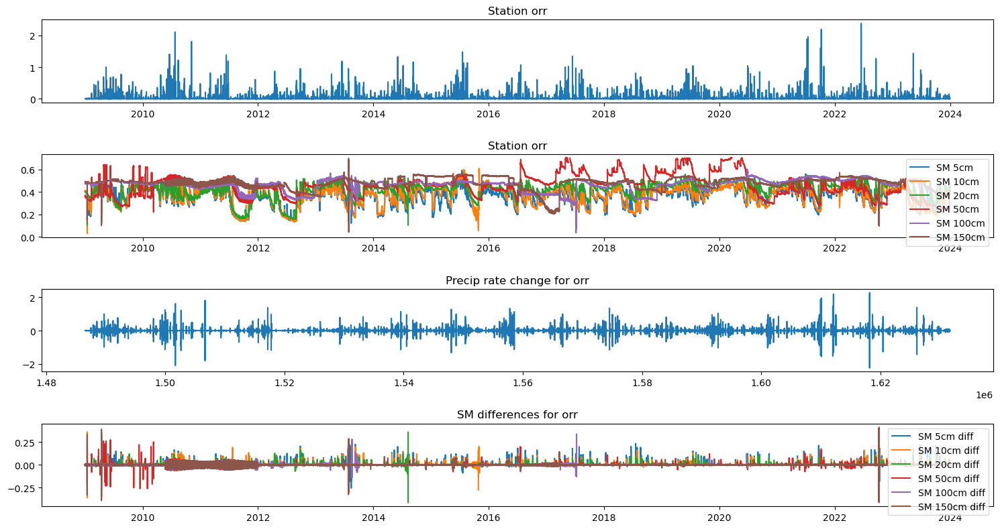

max of precip values 2.474
min of sm values 0.021
max of sm values 0.57


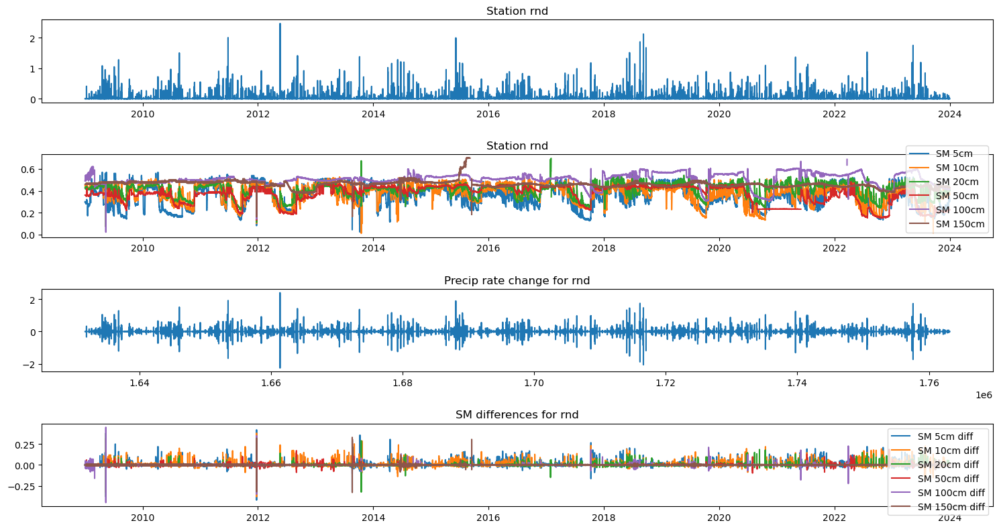

max of precip values 1.943
min of sm values 0.001
max of sm values 0.27


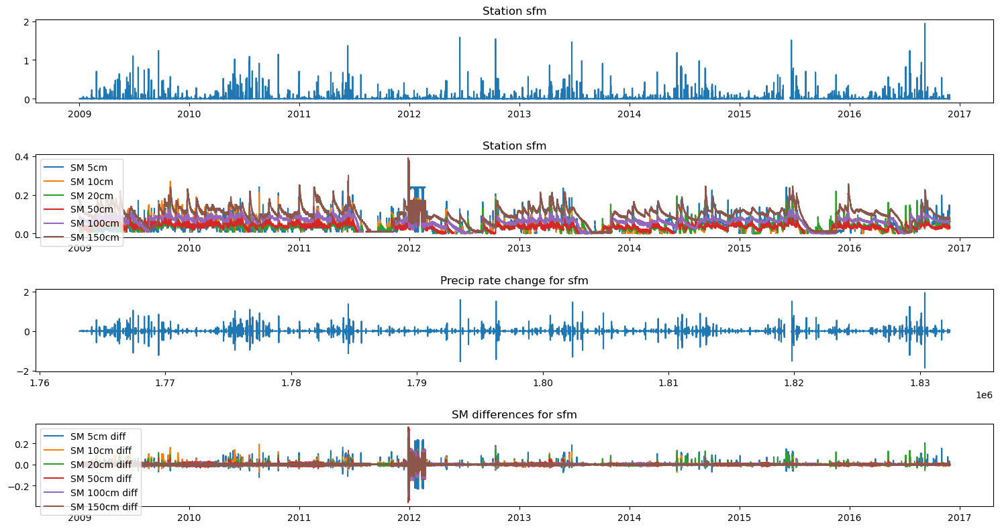

max of precip values 1.66
min of sm values 0.002
max of sm values 0.675


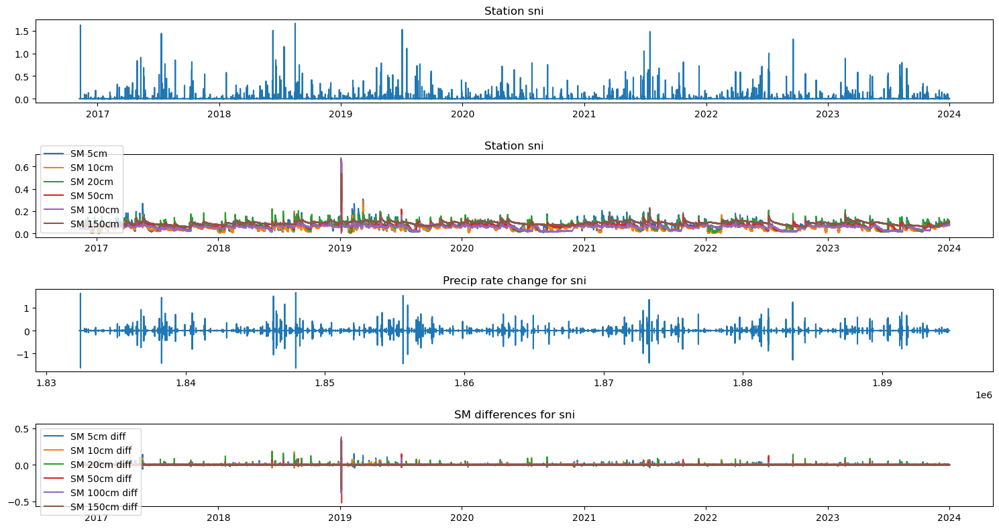

max of precip values 2.889
min of sm values 0.071
max of sm values 0.53


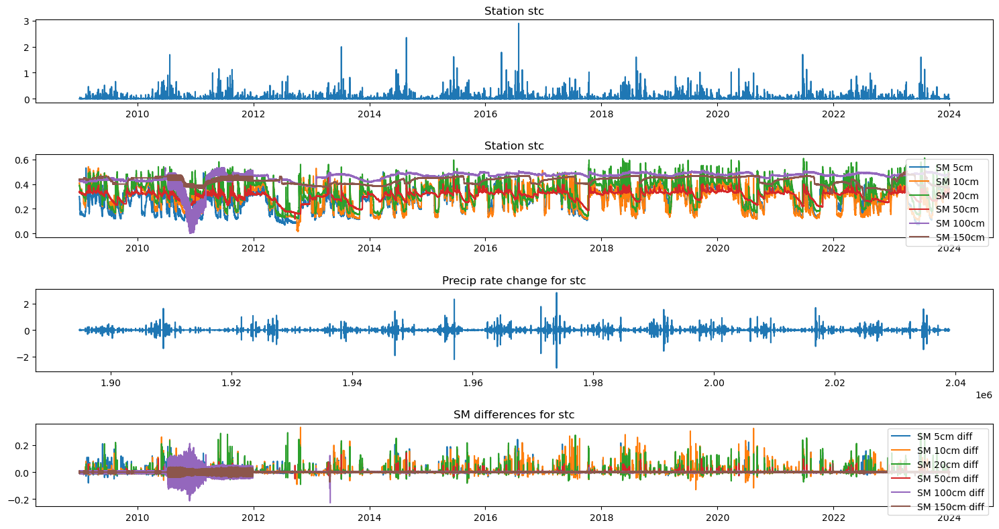

max of precip values 1.772
min of sm values 0.001
max of sm values 0.551


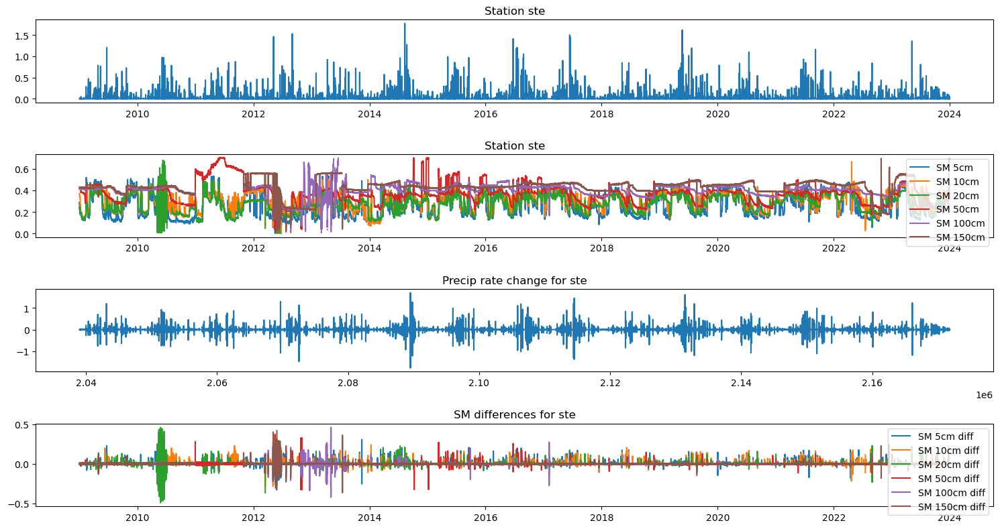

max of precip values 1.894
min of sm values 0.03
max of sm values 0.7


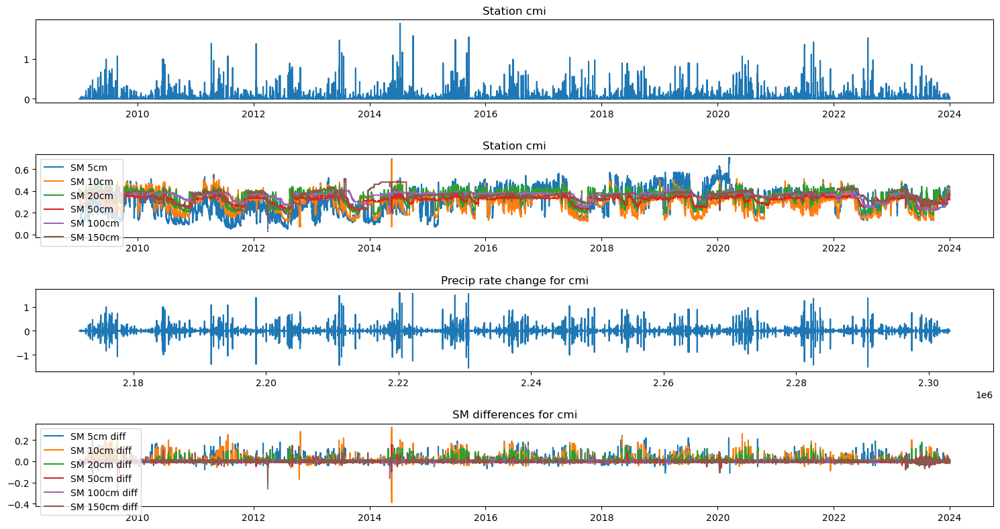

max of precip values 2.192
min of sm values 0.09
max of sm values 0.49


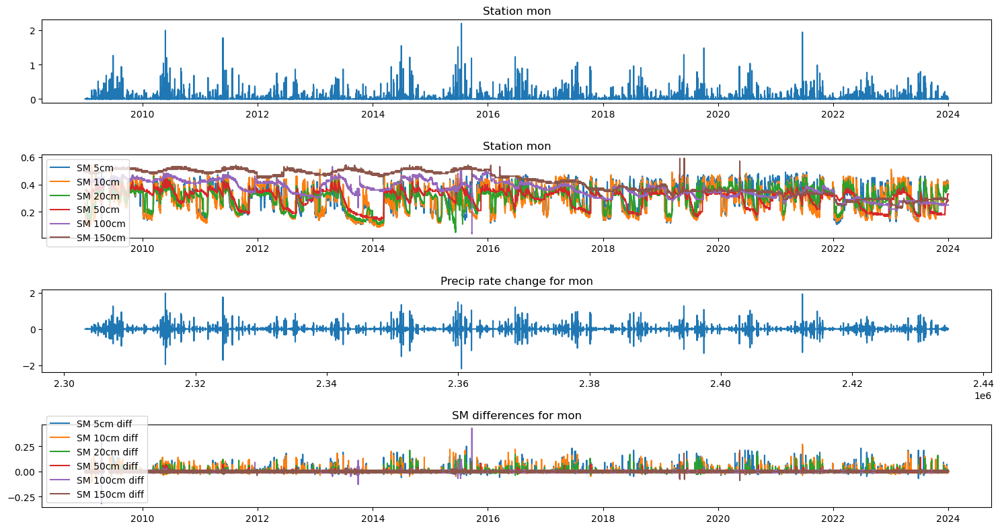

max of precip values 2.794
min of sm values 0.041
max of sm values 0.566


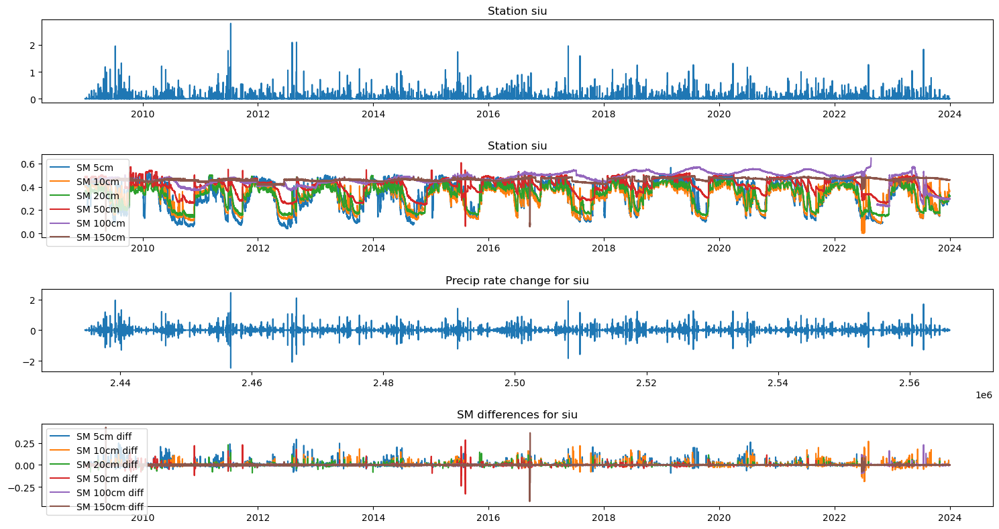

In [8]:
#visualize cleaned and sorted data
Stations = SM_data_cleaned.Station.unique()
Data_column_names = ['Precipitation (in)', 'Soil Moisture 5cm (wfv)', 'Soil Moisture 10cm (wfv)', 
                     'Soil Moisture 20cm (wfv)','Soil Moisture 50cm (wfv)', 
                     'Soil Moisture 100cm (wfv)', 'Soil Moisture 150cm (wfv)']

for S in Stations:
    station_data = SM_data_cleaned.loc[SM_data_cleaned['Station'] == S]
    dtv = station_data['Date & Time (CST)'][:]
    precip_diff = station_data['Precipitation (in)'].diff()

    print('max of precip values', station_data['Precipitation (in)'].max())
    print('min of sm values', station_data['Soil Moisture 5cm (wfv)'].min())
    print('max of sm values', station_data['Soil Moisture 5cm (wfv)'].max())
    fig1, ax1 = plt.subplots(nrows = 4, ncols = 1, figsize = (15,8))

    ax1[0].plot(dtv,station_data['Precipitation (in)'], label = 'Precipitation')
    ax1[1].plot(dtv, station_data['Soil Moisture 5cm (wfv)'], label = 'SM 5cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 10cm (wfv)'], label = 'SM 10cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 20cm (wfv)'], label = 'SM 20cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 50cm (wfv)'], label = 'SM 50cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 100cm (wfv)'], label = 'SM 100cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 150cm (wfv)'], label = 'SM 150cm')
    ax1[1].legend()

    ax1[2].plot(precip_diff)

    ax1[3].plot(dtv, station_data['Soil Moisture 5cm (wfv)'].diff(), label = 'SM 5cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 10cm (wfv)'].diff(), label = 'SM 10cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 20cm (wfv)'].diff(), label = 'SM 20cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 50cm (wfv)'].diff(), label = 'SM 50cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 100cm (wfv)'].diff(), label = 'SM 100cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 150cm (wfv)'].diff(), label = 'SM 150cm diff')
    ax1[3].legend()

    ax1[0].set_title('Station %s' %S)
    ax1[1].set_title('Station %s' %S)
    ax1[2].set_title('Precip rate change for %s' %S)
    ax1[3].set_title('SM differences for %s' %S)
    plt.tight_layout()
    plt.show()


In [9]:
#Look at major event at SIU and BBC for dates to verify if that much rain actually fell or could've
bbc_data = SM_data_cleaned.loc[SM_data_cleaned['Station'] == 'bbc']
siu_data = SM_data_cleaned.loc[SM_data_cleaned['Station'] == 'siu']
brw_data = SM_data_cleaned.loc[SM_data_cleaned['Station'] == 'brw']
ste_data = SM_data_cleaned.loc[SM_data_cleaned['Station'] == 'ste']
fre_data = SM_data_cleaned.loc[SM_data_cleaned['Station'] == 'fre']

fre_data.loc[fre_data['Precipitation (in)'] == fre_data['Precipitation (in)'].max()]

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift
817342,fre,2010-07-24 01:00:00,2.831,0.43,0.52,0.5,0.45,0.51,0.53,2.577,0.254,0.398


In [10]:
siu_data_select = SM_data_cleaned[2463512-10:2463512+10]
bbc_data_select = SM_data_cleaned[32003-10:32003+10]
brw_data_select = SM_data_cleaned[192648-10:192648+10]
ste_data_select = SM_data_cleaned[2104001-10:2104001+10]
fre_data_select = SM_data_cleaned[832569-5:832569+5]

bbc_data_select

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift
31993,bbc,2011-08-08 09:00:00,0.000,0.195,0.248,0.128,0.153,0.096,0.062,0.000,0.000,0.000
31994,bbc,2011-08-08 09:00:00,0.000,0.200,0.250,0.130,0.160,0.100,0.070,0.000,0.000,0.000
31995,bbc,2011-08-08 10:00:00,0.000,0.195,0.248,0.131,0.150,0.094,0.061,0.000,0.000,0.000
31996,bbc,2011-08-08 10:00:00,0.000,0.200,0.250,0.140,0.160,0.100,0.070,0.000,0.000,0.000
31997,bbc,2011-08-08 11:00:00,0.000,0.196,0.248,0.132,0.151,0.096,0.062,0.000,0.000,0.000
31998,bbc,2011-08-08 11:00:00,0.000,0.200,0.250,0.140,0.160,0.100,0.070,0.000,0.000,0.039
31999,bbc,2011-08-08 12:00:00,0.039,0.200,0.250,0.140,0.160,0.100,0.070,0.039,0.000,0.039
32000,bbc,2011-08-08 12:00:00,0.039,0.195,0.248,0.135,0.151,0.096,0.062,0.000,0.039,0.598
32001,bbc,2011-08-08 13:00:00,0.598,0.250,0.250,0.140,0.150,0.100,0.070,0.559,0.039,0.598
32002,bbc,2011-08-08 13:00:00,0.598,0.246,0.249,0.132,0.148,0.093,0.063,0.000,0.598,NaN


In [11]:
Column_sum_depth = [10, 100]
sensor_depths = np.array([5, 10, 20, 50, 100, 150])

#Column_depth is Column_sum_depth, and depths is sensor_depths
def column_weighted_sm(data, Column_depth, depths):
    for m in range(len(Column_depth)):
        n = np.where(sensor_depths == Column_depth[m])[0][0]
        depth_weights = np.zeros(len(depths))
        Weighted_column_names = str(Column_depth[m]) + 'cm_weighted_col_sm'

        for r in range(len(sensor_depths[0:n]) + 1):
            if r == 0:
                depth_weights[r] = (((sensor_depths[r+1] - sensor_depths[r])/2 + 
                                     sensor_depths[r])/Column_depth[m])
            elif ((r >= 0) and (r < len(sensor_depths[0:n])-1)):
                depth_weights[r] = ((sensor_depths[r+1] - sensor_depths[r-1])/2)/Column_depth[m] 
            else:
                depth_weights[r] = ((sensor_depths[r] - sensor_depths[r-1])/2)/Column_depth[m]
        print('depth weights =', depth_weights)

        for c in range(len(sensor_depths[0:n]) + 1):
            if c == 0:
                data[Weighted_column_names] = depth_weights[c] * data.iloc[:,c + 3]
            else:
                data[Weighted_column_names] =( data[Weighted_column_names] +
                                              depth_weights[c] * data.iloc[:,c + 3])

    return data

SM_data_weighted = column_weighted_sm(SM_data_cleaned, Column_sum_depth, sensor_depths)
SM_data_weighted.head()    

depth weights = [0.75 0.25 0.   0.   0.   0.  ]
depth weights = [0.075 0.075 0.2   0.15  0.25  0.   ]


,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift,10cm_weighted_col_sm,100cm_weighted_col_sm
0,bbc,2009-01-01 00:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.08,NaN,NaN,0.0,0.2725,0.15775
1,bbc,2009-01-01 01:00:00,0.0,0.27,0.28,0.2,0.22,0.18,0.08,0.0,0.0,0.0,0.2725,0.15925
2,bbc,2009-01-01 02:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0,0.2725,0.15775
3,bbc,2009-01-01 03:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0,0.2725,0.15775
4,bbc,2009-01-01 04:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0,0.2725,0.15775


Missing some stations, no champaign station cci

## Partition storm events: 0 rain for 24 consecutive hours (eventually switch to 20/24 maybe)

ID indices for beginning and end of dry periods, subtract the difference and locate the dry periods 
greater than 24 hours and set those to be the cut off of the storm 

# assign last portion of data for each station that is less than consecutive dry hours to be False as we cannot no for certain if it meets the dry period cutoff definition

In [12]:
consecutive_dry_hours = 24
def precip_event_ID(data, hours):
    #min_num_dry_hours = np.floor(hours * 0.843) #(20/24)=0.8333333 same for 30/36
    Stations = data.Station.unique()
    data['Rain_ID'] = (data['Precipitation (in)'] > 0).astype(int)
    data['Rain_ID_lag'] = data['Rain_ID'].shift(1)
    for s in Stations:
        beginning_of_station = data.loc[data['Station'] == s].index[0]
        data.iloc[beginning_of_station, 12] = np.NaN       

    data['Rain_ID_diff'] = data['Rain_ID'].sub(data['Rain_ID_lag'], axis = 0) #values of -1 in this column will always represent when a dry period started

    data['Dry_periods'] = data['Rain_ID_diff']
    data['Dry_periods'] = data['Dry_periods'].replace(1, -1) #now the days when dry periods start and end are 
    #represented as -1. Use index to grab the indices of these dates and subtract
    
    data['Dry_periods_overmin'] = False #set to false, find indices over 24 from dry period indices 
    #spacing and replace those with TRUE then select those with 
    print(Stations)
    for sn in Stations:
        station_data = data.loc[data['Station'] == sn]
        dry_period_indices = pd.Series(station_data.loc[station_data['Dry_periods'] == -1].index)
        dry_period_indices_spacing = dry_period_indices.diff()
        dry_period_indices_spacing_shifted = dry_period_indices_spacing.shift(-1) #aligning period lengths with the index they start with 
        dry_period_indices_spacing_shifted[-1:] = station_data.Dry_periods.index[-1:] - dry_period_indices[-1:]
        dry_over_consec_min = (dry_period_indices_spacing_shifted >= hours)
        dry_periods = pd.concat([dry_period_indices, dry_period_indices_spacing_shifted], axis = 1)
        dry_periods = dry_periods.loc[dry_over_consec_min]
        
        data.iloc[dry_periods[0], 18] = True
        
        beginning_of_station = data.loc[data['Station'] == sn].index[0]
        #assign last portion of data for each station that is less than consecutive dry hours to be 
        #False as we cannot no for certain if it meets the dry period cutoff definition
        data.iloc[beginning_of_station - consecutive_dry_hours:beginning_of_station + 1, 18] = False


    return data

WeightedSM_data_stormID = precip_event_ID(SM_data_weighted, consecutive_dry_hours)

['bbc' 'brw' 'bvl' 'dek' 'dxs' 'fai' 'fre' 'frm' 'icc' 'llc' 'oln' 'orr'
 'rnd' 'sfm' 'sni' 'stc' 'ste' 'cmi' 'mon' 'siu']


In [13]:
WeightedSM_data_stormID

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift,10cm_weighted_col_sm,100cm_weighted_col_sm,Rain_ID,Rain_ID_lag,Rain_ID_diff,Dry_periods,Dry_periods_overmin
0,bbc,2009-01-01 00:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.080,NaN,NaN,0.0,NaN,0.157750,0,NaN,NaN,NaN,False
1,bbc,2009-01-01 01:00:00,0.0,0.270,0.280,0.200,0.220,0.180,0.080,0.0,0.0,0.0,0.27250,0.159250,0,0.0,0.0,0.0,False
2,bbc,2009-01-01 02:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.090,0.0,0.0,0.0,0.27250,0.157750,0,0.0,0.0,0.0,False
3,bbc,2009-01-01 03:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.090,0.0,0.0,0.0,0.27250,0.157750,0,0.0,0.0,0.0,False
4,bbc,2009-01-01 04:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.090,0.0,0.0,0.0,0.27250,0.157750,0,0.0,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2566102,siu,2023-12-31 20:00:00,0.0,0.317,0.362,0.322,0.298,0.298,0.461,0.0,0.0,0.0,0.32825,0.234525,0,0.0,0.0,0.0,False
2566103,siu,2023-12-31 21:00:00,0.0,0.318,0.362,0.323,0.299,0.297,0.461,0.0,0.0,0.0,0.32900,0.234700,0,0.0,0.0,0.0,False
2566104,siu,2023-12-31 22:00:00,0.0,0.317,0.361,0.323,0.300,0.295,0.461,0.0,0.0,0.0,0.32800,0.234200,0,0.0,0.0,0.0,False
2566105,siu,2023-12-31 23:00:00,0.0,0.317,0.361,0.323,0.298,0.296,0.461,0.0,0.0,0.0,0.32800,0.234150,0,0.0,0.0,0.0,False


### select rows where Rain_ID_diff = -1 (beginning of dry period) and Dry_periods_over24 = True this is where the storm event ends
### Rain_ID_diff = 1 is beginning
select sm for timestep before beginning

variables to pull for each event (1 data point per evvent): sm-1, max_sm, average precip rate and peak precip, 

## note that sometimes the first point in the dataset has raining and is taken as the start but we don't know if it is and we don't have the prior sm should we throw these events out then? Yes, events are deleted

bbc
true event start index [71.0, 138.0, 194.0, 278.0]
true event end indices [75, 140, 252, 282]
length of the initial events = 4.0
length of the initial events = 2.0
length of the initial events = 58.0
length of the initial events = 4.0


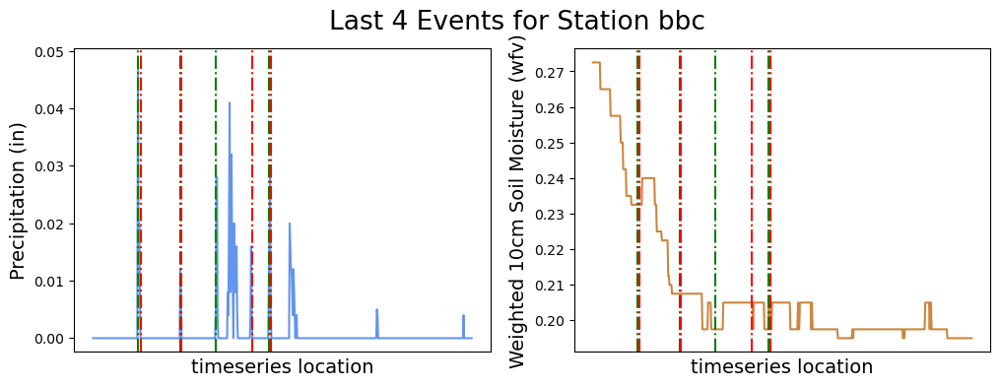

brw
true event start index [144259.0, 144308.0, 144338.0, 144398.0]
true event end indices [144262, 144312, 144350, 144409]
length of the initial events = 3.0
length of the initial events = 4.0
length of the initial events = 12.0
length of the initial events = 11.0


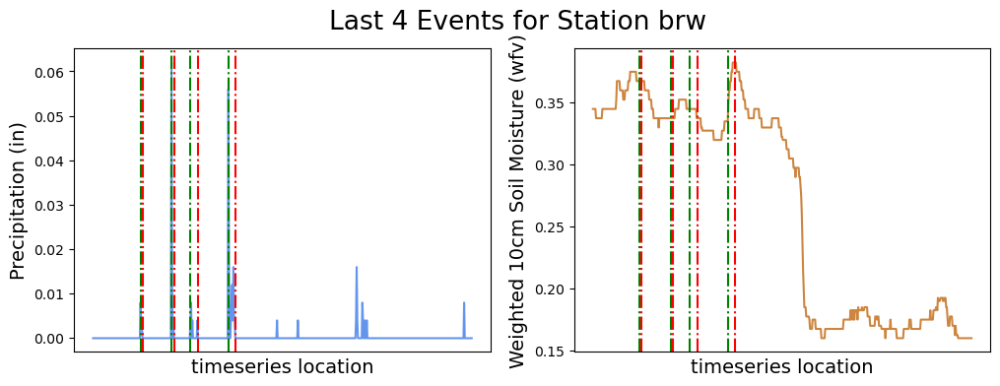

bvl
true event start index [276614.0, 276678.0, 276737.0, 276938.0]
true event end indices [276615, 276679, 276860, 276967]
length of the initial events = 1.0
length of the initial events = 1.0
length of the initial events = 123.0
length of the initial events = 29.0


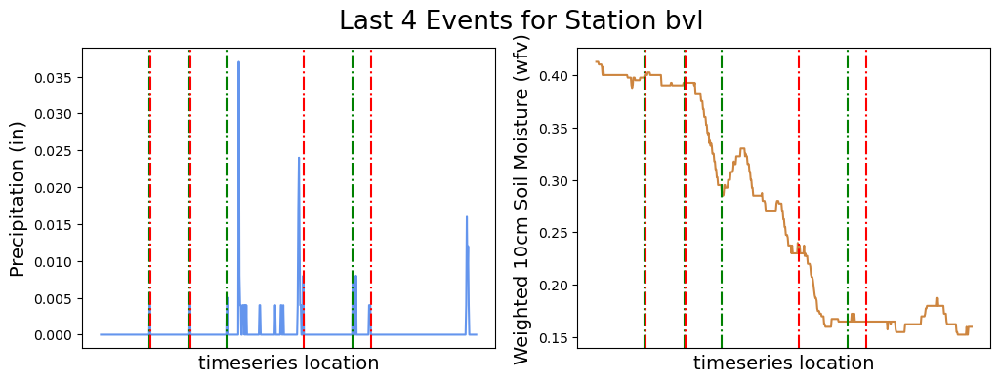

dek
true event start index [409535.0, 409592.0, 409658.0, 409744.0]
true event end indices [409539, 409622, 409690, 409746]
length of the initial events = 4.0
length of the initial events = 30.0
length of the initial events = 32.0
length of the initial events = 2.0


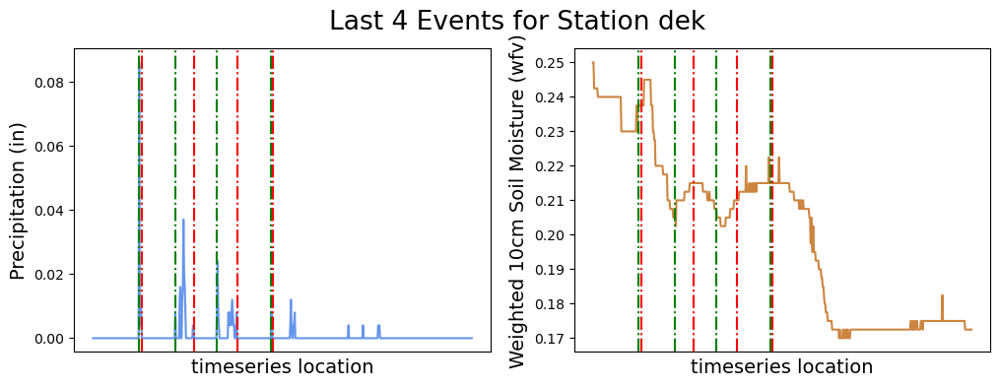

dxs
true event start index [540979.0, 541041.0, 541141.0, 541202.0]
true event end indices [541003, 541077, 541146, 541203]
length of the initial events = 24.0
length of the initial events = 36.0
length of the initial events = 5.0
length of the initial events = 1.0


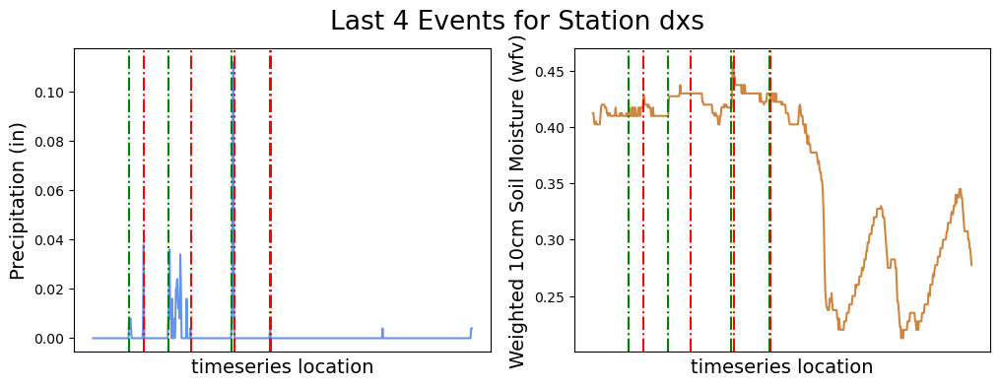

fai
true event start index [672389.0, 672452.0, 672547.0, 672747.0]
true event end indices [672400, 672479, 672551, 672765]
length of the initial events = 11.0
length of the initial events = 27.0
length of the initial events = 4.0
length of the initial events = 18.0


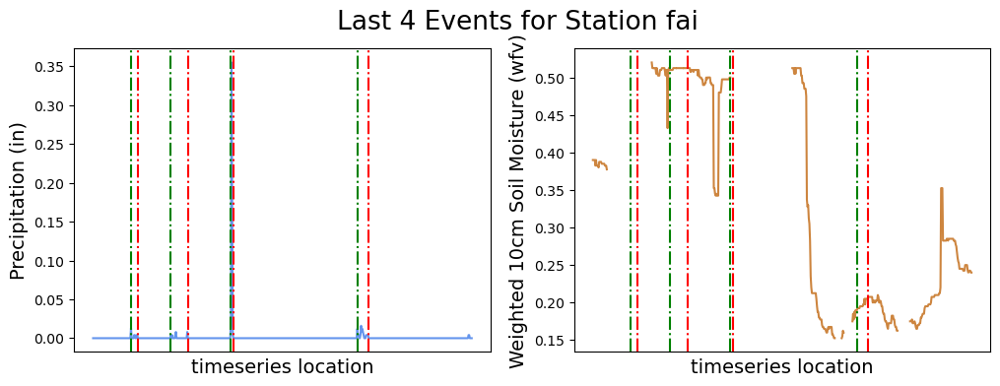

fre
true event start index [803756.0, 803880.0, 803964.0, 804134.0]
true event end indices [803760, 803939, 804007, 804138]
length of the initial events = 4.0
length of the initial events = 59.0
length of the initial events = 43.0
length of the initial events = 4.0


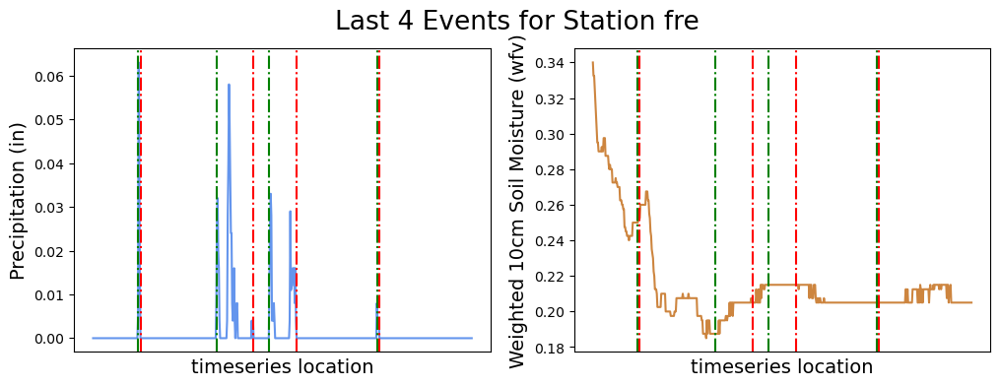

frm
true event start index [935209.0, 935271.0, 935307.0, 935337.0]
true event end indices [935231, 935272, 935308, 935440]
length of the initial events = 22.0
length of the initial events = 1.0
length of the initial events = 1.0
length of the initial events = 103.0


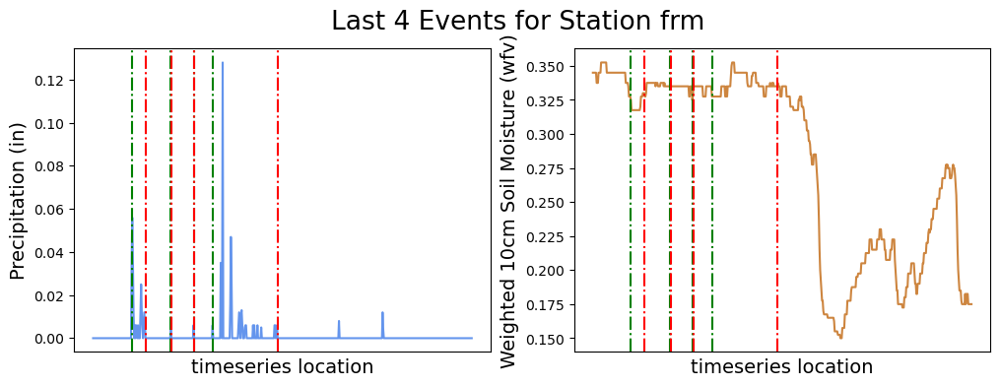

icc
true event start index [1075609.0, 1075674.0, 1075766.0, 1075826.0]
true event end indices [1075623, 1075691, 1075799, 1075832]
length of the initial events = 14.0
length of the initial events = 17.0
length of the initial events = 33.0
length of the initial events = 6.0


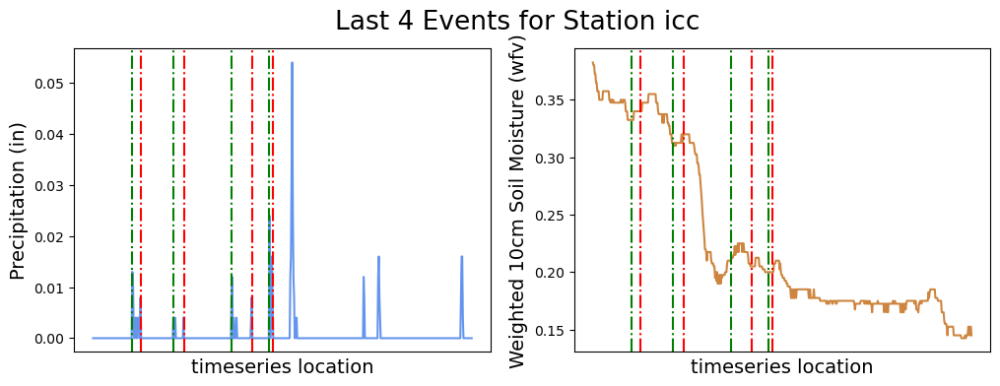

llc
true event start index [1218323.0, 1218379.0, 1218470.0, 1218542.0]
true event end indices [1218329, 1218381, 1218476, 1218543]
length of the initial events = 6.0
length of the initial events = 2.0
length of the initial events = 6.0
length of the initial events = 1.0


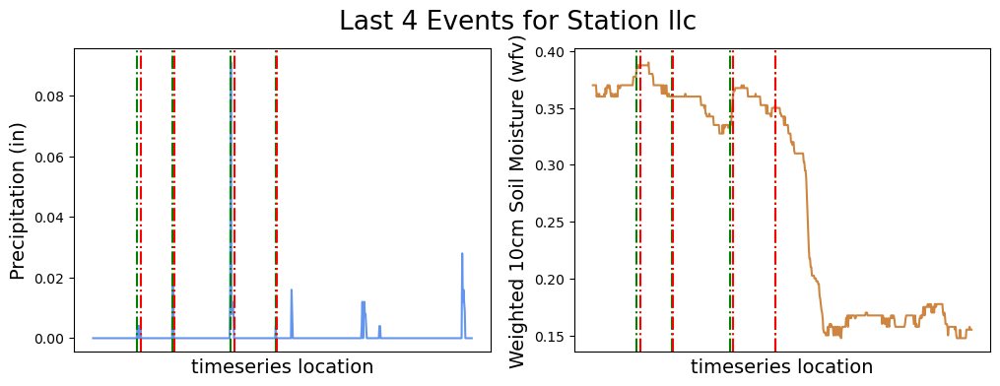

oln
true event start index [1350458.0, 1350521.0, 1350615.0, 1350814.0]
true event end indices [1350469, 1350547, 1350621, 1350832]
length of the initial events = 11.0
length of the initial events = 26.0
length of the initial events = 6.0
length of the initial events = 18.0


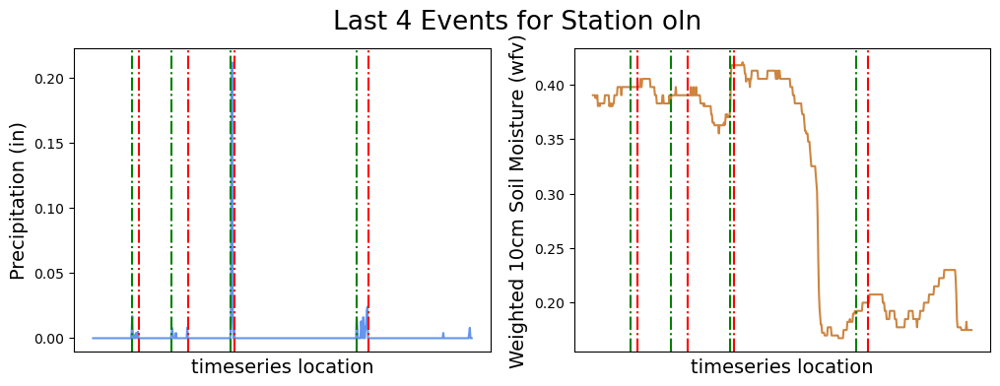

orr
true event start index [1486653.0, 1486686.0, 1486740.0, 1486801.0]
true event end indices [1486654, 1486687, 1486741, 1486812]
length of the initial events = 1.0
length of the initial events = 1.0
length of the initial events = 1.0
length of the initial events = 11.0


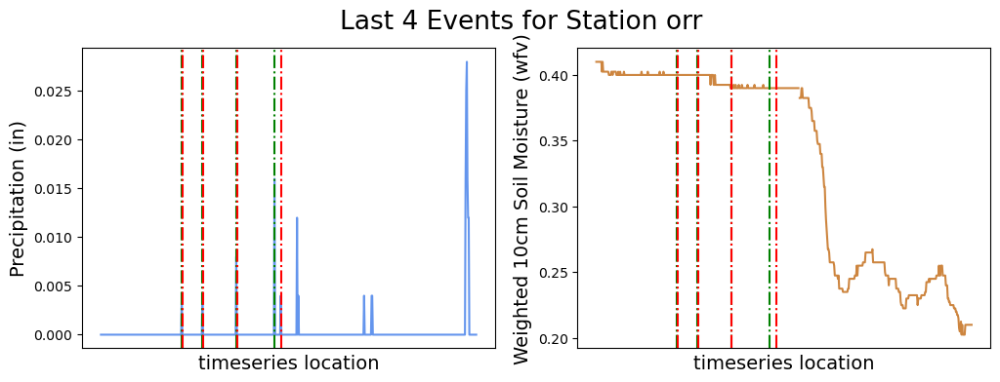

rnd
true event start index [1631778.0, 1631847.0, 1631935.0, 1632145.0]
true event end indices [1631783, 1631848, 1631938, 1632146]
length of the initial events = 5.0
length of the initial events = 1.0
length of the initial events = 3.0
length of the initial events = 1.0


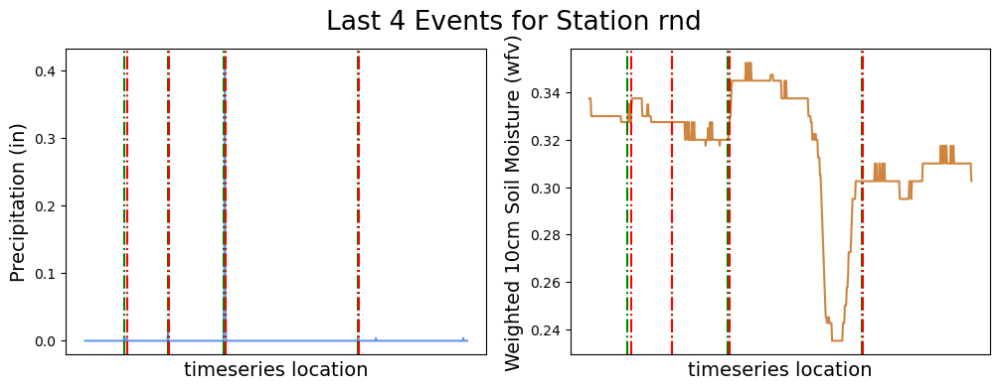

sfm
true event start index [1763241.0, 1763295.0, 1763386.0, 1763447.0]
true event end indices [1763244, 1763300, 1763388, 1763458]
length of the initial events = 3.0
length of the initial events = 5.0
length of the initial events = 2.0
length of the initial events = 11.0


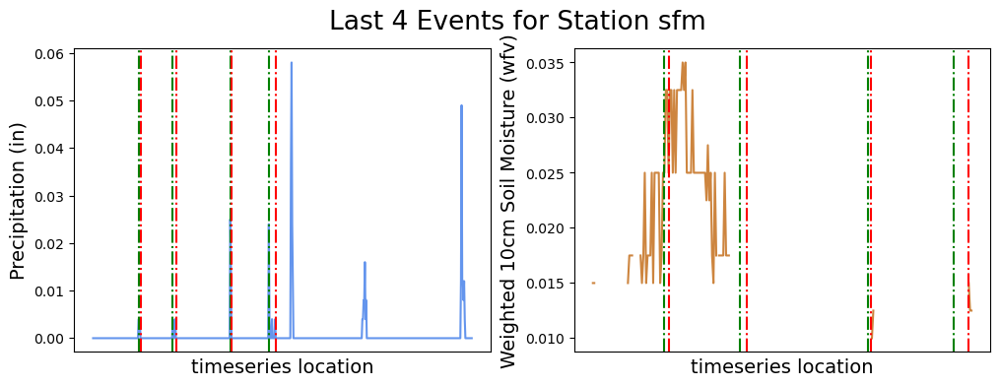

sni
true event start index [1832447.0, 1832636.0, 1832738.0, 1832857.0]
true event end indices [1832448, 1832654, 1832743, 1832882]
length of the initial events = 1.0
length of the initial events = 18.0
length of the initial events = 5.0
length of the initial events = 25.0


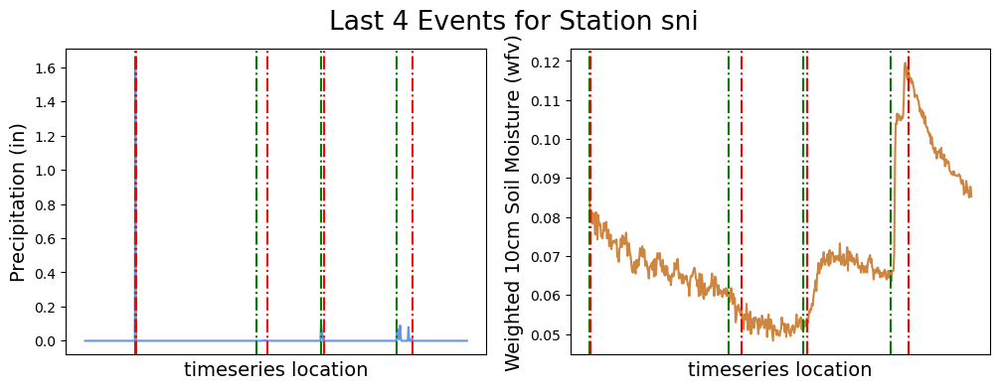

stc
true event start index [1894905.0, 1894965.0, 1895032.0, 1895117.0]
true event end indices [1894914, 1894984, 1895068, 1895121]
length of the initial events = 9.0
length of the initial events = 19.0
length of the initial events = 36.0
length of the initial events = 4.0


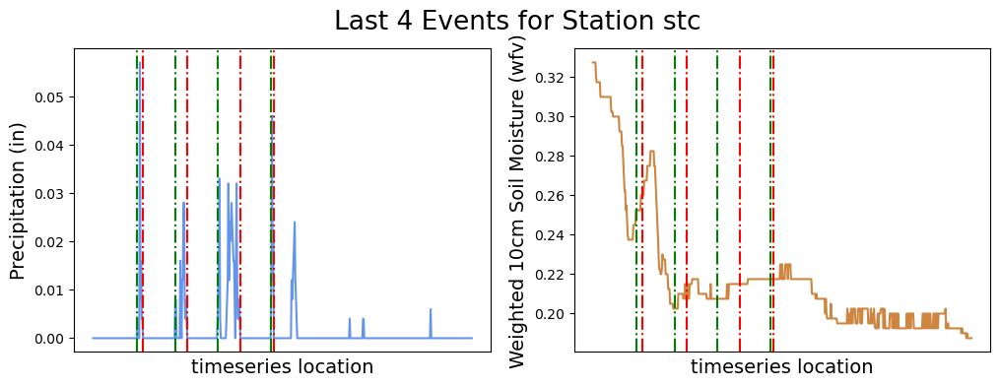

ste
true event start index [2039082.0, 2039132.0, 2039203.0, 2039286.0]
true event end indices [2039085, 2039170, 2039235, 2039324]
length of the initial events = 3.0
length of the initial events = 38.0
length of the initial events = 32.0
length of the initial events = 38.0


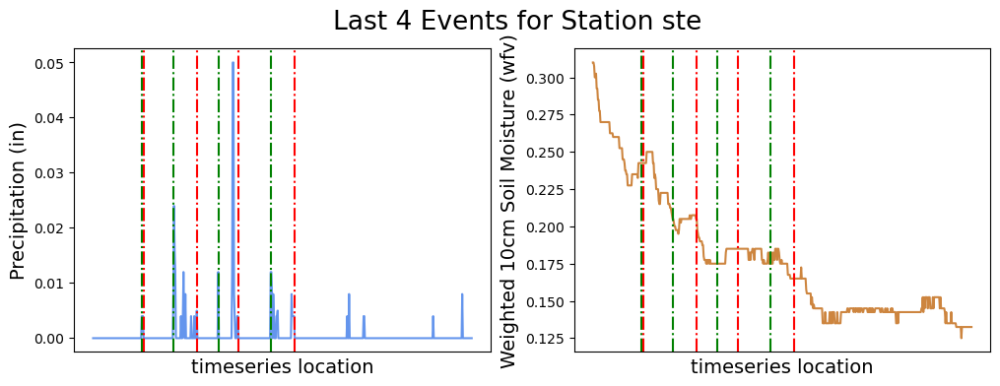

cmi
true event start index [2171909.0, 2171973.0, 2172051.0, 2172085.0]
true event end indices [2171910, 2171974, 2172054, 2172151]
length of the initial events = 1.0
length of the initial events = 1.0
length of the initial events = 3.0
length of the initial events = 66.0


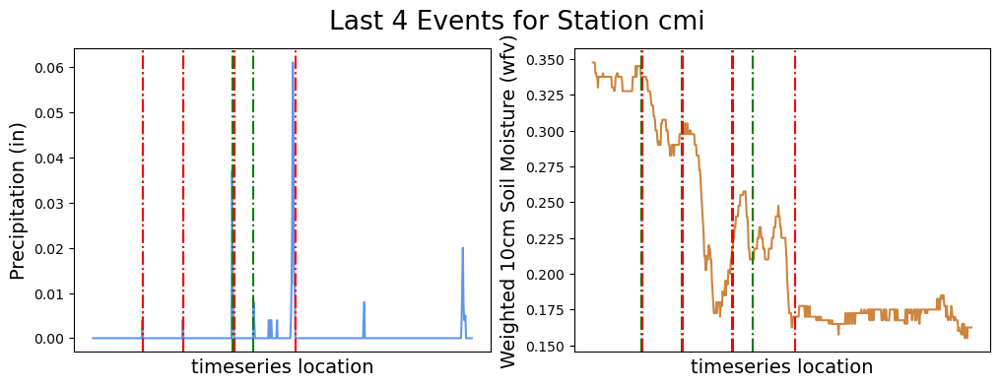

mon
true event start index [2303258.0, 2303408.0, 2303468.0, 2303502.0]
true event end indices [2303264, 2303417, 2303471, 2303512]
length of the initial events = 6.0
length of the initial events = 9.0
length of the initial events = 3.0
length of the initial events = 10.0


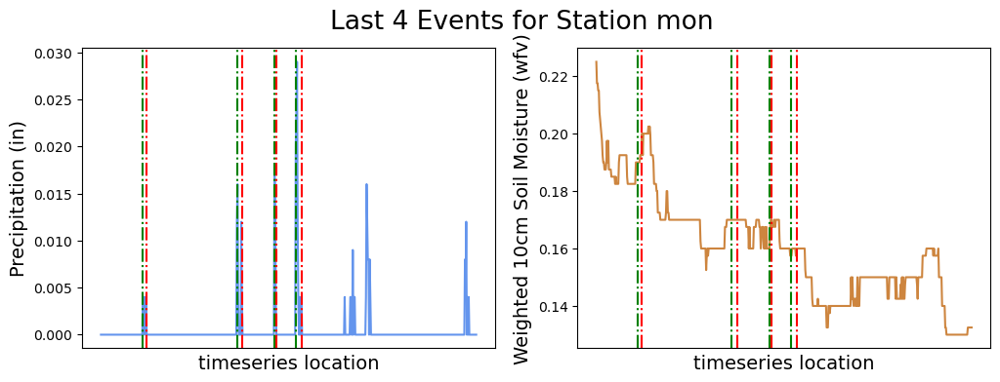

siu
true event start index [2434715.0, 2434778.0, 2434875.0, 2435277.0]
true event end indices [2434716, 2434790, 2434877, 2435319]
length of the initial events = 1.0
length of the initial events = 12.0
length of the initial events = 2.0
length of the initial events = 42.0


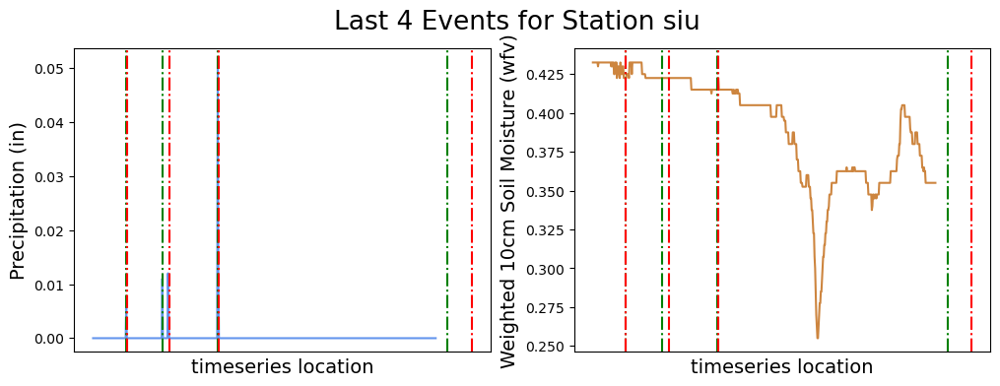

22787
22787


In [14]:
def Rain_events_data(data):
    Stations = data.Station.unique() 
    df_counter = 0

    #create new dataframe and asign data and station ID to it columnnames 
    #['Station', 'Avg_Precipitation_rate_in', 'Peak_Precipitation_rate_in', 
    #'Median_Precipitation_rate_in', 'Prior_sm_10', 'peak_sm_10' ,'Prior_sm_100', 'peak_sm_100']
    new_df = pd.DataFrame(columns = ['Station', 'Avg_Precipitation_rate_in', 'Peak_Precipitation_rate_in', 
    'Median_Precipitation_rate_in', 'Total_Precipitation_in', 'Prior_sm_10', 'Peak_sm_10' ,
    'Prior_sm_100', 'Peak_sm_100'])

    full_prior_sm_10 = pd.Series()
    full_peak_sm_10 = pd.Series()
    full_prior_sm_100 = pd.Series()
    full_peak_sm_100 = pd.Series()
    full_Precip_peak_rate = pd.Series()
    full_Precip_avg_rate = pd.Series()
    full_Precip_med_rate = pd.Series()
    full_Precip_total = pd.Series()
    station_id_series = pd.Series()

    for sn in Stations:
        print(sn)
        station_data = data.loc[data['Station'] == sn]
        first_event_beginning_index = pd.Series(station_data.loc[station_data['Rain_ID'] == 1].index[0])
        
        event_ending_indices = pd.Series(station_data.loc[(station_data['Rain_ID_diff'] == -1) & 
                                                (station_data['Dry_periods_overmin'] == True)].index)
        
        raining_begins_again = pd.Series(station_data.loc[station_data['Rain_ID_diff'] == 1].index)
        
        true_event_start = pd.Series(np.zeros(len(event_ending_indices))) #there should be the same number for starts as finishes
        true_event_start[0] = first_event_beginning_index.iloc[0]

        prior_sm_10 = pd.Series(np.zeros(len(event_ending_indices)))
        peak_sm_10 = pd.Series(np.zeros(len(event_ending_indices)))
        prior_sm_100 = pd.Series(np.zeros(len(event_ending_indices)))
        peak_sm_100 = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_peak_rate = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_avg_rate = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_med_rate = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_total = pd.Series(np.zeros(len(event_ending_indices)))

        prior_sm_10[0] = data.iloc[true_event_start[0].astype(int)-1, 12]
        prior_sm_100[0] = data.iloc[true_event_start[0].astype(int)-1, 13]


        peak_sm_10[0] = data.iloc[true_event_start[0].astype(int):event_ending_indices[0].astype(int), 12].max()
        peak_sm_100[0] = data.iloc[true_event_start[0].astype(int):event_ending_indices[0].astype(int), 13].max()
        Precip_peak_rate[0] = data.iloc[true_event_start[0].astype(int):event_ending_indices[0].astype(int), 2].max()
        Precip_avg_rate[0] = data.iloc[true_event_start[0].astype(int):event_ending_indices[0].astype(int), 2].mean()
        Precip_med_rate[0] = data.iloc[true_event_start[0].astype(int):event_ending_indices[0].astype(int), 2].median()
        Precip_total[0] = data.iloc[true_event_start[0].astype(int):event_ending_indices[0].astype(int), 2].sum()              
        counter = 0
        #pull out the true event starts
        for n in range(len(raining_begins_again)-1):

            if counter == len(event_ending_indices)-1:
                
                break
            else:
                if raining_begins_again[n] <= event_ending_indices[counter]:
                    continue #skip to next n until one after event ending
                else:
                    true_event_start[counter + 1] = raining_begins_again[n]
            
                    #pull out variables between start and end of events and put into pd.series to assign to newdf below
                    prior_sm_10[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int)-1, 12]
                    prior_sm_100[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int)-1, 13]
                    peak_sm_10[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int):event_ending_indices[counter + 1].astype(int), 12].max()
                    peak_sm_100[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int):event_ending_indices[counter + 1].astype(int), 13].max()
                    Precip_peak_rate[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int):event_ending_indices[counter + 1].astype(int), 2].max()
                    Precip_avg_rate[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int):event_ending_indices[counter + 1].astype(int), 2].mean()
                    Precip_med_rate[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int):event_ending_indices[counter + 1].astype(int), 2].median()
                    Precip_total[counter + 1] = data.iloc[true_event_start[counter + 1].astype(int):event_ending_indices[counter + 1].astype(int), 2].sum()

                    counter +=1
            #throw out first event if it begins at the beginning of the time series as we do not 
            # know when it actually started
        if first_event_beginning_index.iloc[0] == 0:
            true_event_start = true_event_start[1:]
            event_ending_indices = event_ending_indices[1:]
            prior_sm_10 = prior_sm_10[1:]
            prior_sm_100 = prior_sm_100[1:]
            peak_sm_10 = peak_sm_10[1:]
            peak_sm_100 = peak_sm_100[1:]
            Precip_avg_rate = Precip_avg_rate[1:]
            Precip_med_rate = Precip_med_rate[1:]
            Precip_total =  Precip_total[1:]
            Precip_peak_rate = Precip_peak_rate[1:]

        #last_precip_marker = station_data.loc[station_data['Rain_ID']==1].index[-1:]
        #print('index of last precipitation', last_precip_marker)
        #last_datapoint = station_data.Rain_ID.index[-1:]
        #print('length of station data',last_datapoint )
        precip = station_data['Precipitation (in)'][:600]
        sm_10 = station_data['10cm_weighted_col_sm'][:600]
        fig, ax = plt.subplots(nrows =1, ncols =2, figsize = (12,4))
        ax[0].plot(precip, color = 'cornflowerblue')
        #x = event_ending_indices[len(event_ending_indices)-1]
        #ax.axvline(x=x, color ='red')
        
        ax[0].set_ylabel('Precipitation (in)', fontsize = 14)
        ax[0].set_xlabel('timeseries location', fontsize = 14)
        ax[0].set_xticks([])

        ax[1].plot(sm_10, color = 'peru')
        #ax[1].set_title('Last four events for station %s' % sn, fontsize = 19)
        ax[1].set_ylabel('Weighted 10cm Soil Moisture (wfv)', fontsize = 14)
        ax[1].set_xlabel('timeseries location', fontsize = 14)
        ax[1].set_xticks([])

        fig.suptitle('Last 4 Events for Station %s' % sn, fontsize = 19)
        event_number = 4

        Last_4_start_times =true_event_start[:event_number].tolist()
        print('true event start index',Last_4_start_times)
        Last_4_end_times = event_ending_indices[:event_number].tolist()
        print('true event end indices', Last_4_end_times)
        
        for v in range(event_number):
            print('length of the initial events =',(Last_4_end_times[v] - Last_4_start_times[v]))
            ax[0].axvline(x = Last_4_start_times[v], color = 'green', linestyle = '-.')
            ax[0].axvline(x = Last_4_end_times[v], color = 'red', linestyle = '-.')
            ax[1].axvline(x = Last_4_start_times[v], color = 'green', linestyle = '-.')
            ax[1].axvline(x = Last_4_end_times[v], color = 'red', linestyle = '-.')
        
        plt.show()

        station_id_series_current_loop = pd.Series(np.repeat(sn, len(event_ending_indices)))


        if df_counter == 0:
            #for first iteration with first station
            full_prior_sm_10 = prior_sm_10
            full_peak_sm_10 = peak_sm_10
            full_prior_sm_100 = prior_sm_100
            full_peak_sm_100 = peak_sm_100
            full_Precip_peak_rate = Precip_peak_rate
            full_Precip_avg_rate = Precip_avg_rate
            full_Precip_med_rate = Precip_med_rate
            full_Precip_total = Precip_total
            station_id_series = station_id_series_current_loop
        else:
            #for after first station, concat vertically
            full_prior_sm_10 = pd.concat([full_prior_sm_10, prior_sm_10], axis = 0)
            full_peak_sm_10 = pd.concat([full_peak_sm_10, peak_sm_10], axis = 0)
            full_prior_sm_100 = pd.concat([full_prior_sm_100, prior_sm_100], axis = 0)
            full_peak_sm_100 = pd.concat([full_peak_sm_100, peak_sm_100], axis = 0)
            full_Precip_peak_rate = pd.concat([full_Precip_peak_rate, Precip_peak_rate], axis = 0)
            full_Precip_avg_rate = pd.concat([full_Precip_avg_rate, Precip_avg_rate], axis = 0)
            full_Precip_med_rate = pd.concat([full_Precip_med_rate, Precip_med_rate], axis = 0)
            full_Precip_total = pd.concat([full_Precip_total, Precip_total], axis = 0)
            station_id_series = pd.concat([station_id_series, station_id_series_current_loop], axis = 0)

        df_counter += 1
    print(len(full_peak_sm_10))
    print(len(full_Precip_avg_rate))

    station_id_series, full_Precip_avg_rate, full_Precip_med_rate, full_Precip_peak_rate, full_Precip_total, full_prior_sm_10, full_peak_sm_10, full_prior_sm_100, full_peak_sm_100 = [
        s.reset_index(drop = True) for s in [ station_id_series, full_Precip_avg_rate, 
                                             full_Precip_med_rate, full_Precip_peak_rate, 
                                             full_Precip_total, full_prior_sm_10, full_peak_sm_10, 
                                             full_prior_sm_100, full_peak_sm_100]
    ]

    #station_id_series = station_id_series.reset_index(drop = True)

    #['Station', 'Avg_Precipitation_rate_in', 'Peak_Precipitation_rate_in', 
    #'Median_Precipitation_rate_in', 'Prior_sm_10', 'Peak_sm_10' ,'Prior_sm_100', 'Peak_sm_100']
    new_df = new_df.assign(Station = station_id_series,
                           Avg_Precipitation_rate_in = full_Precip_avg_rate,
                           Peak_Precipitation_rate_in = full_Precip_peak_rate,
                           Median_Precipitation_rate_in = full_Precip_med_rate,
                           Total_Precipitation_in = full_Precip_total,
                           Prior_sm_10 = full_prior_sm_10,
                           Peak_sm_10 = full_peak_sm_10,
                           Prior_sm_100 = full_prior_sm_100,
                           Peak_sm_100 = full_peak_sm_100)
    
    #delete rows with Nan values because the kde gaussian function cannot handle the nans 
    #and keeping one column in a row for data but not another (when only the sm or rain gauge is out
    #for a row) makes mapping values to eachother impossbile so mutual information cannot be 
    # appropriately informed need to be able to calc. p(xi, yi)

    new_df = new_df.dropna(how = 'any')

    return new_df


Event_vars_df = Rain_events_data(WeightedSM_data_stormID) 

In [15]:
Event_vars_df.isna().sum()

Station                         0
Avg_Precipitation_rate_in       0
Peak_Precipitation_rate_in      0
Median_Precipitation_rate_in    0
Total_Precipitation_in          0
Prior_sm_10                     0
Peak_sm_10                      0
Prior_sm_100                    0
Peak_sm_100                     0
dtype: int64

### PDF estimation with KDE, binwidth method options are scott or silvermann, using scott's method as it is more robust for non-normally distributed data with skewness, which is precip data
https://ntnuopen.ntnu.no/ntnu-xmlui/bitstream/handle/11250/258553/348940_FULLTEXT01.pdf?sequence=1&isAllowed=y
https://www.umiacs.umd.edu/labs/cvl/pirl/vikas/publications/optimal_bw_slides.pdf

Goodwell and Kumar used Silverman it seems based on their citations of Silverman

set up pdf_generation function to be expandable to any number of columns (1st time through we are only using sm for 10 cm and 100cm)
also set up to be expandable to the number of stations incase we were to give this more station data from other states

In [16]:
#adjut data within function to be dictionary of multiple dfs
def Layer_dfs(data):
    data_columns = data.columns[1:]
    Stations = data.Station.unique()
    multi_dfs = {} #make dictionary of multiple dfs
    for d in Stations:
        print(f'Creating df for {d}')
        #initialize empty single df
        single_df = pd.DataFrame()
        for col in data_columns:
            single_df[col] = data.loc[data.Station == d, col]
        #store single df in dictionary of multiple dfs

        multi_dfs[d] = single_df
    return multi_dfs
station_dfs = Layer_dfs(Event_vars_df)

Creating df for bbc
Creating df for brw
Creating df for bvl
Creating df for dek
Creating df for dxs
Creating df for fai
Creating df for fre
Creating df for frm


Creating df for icc
Creating df for llc
Creating df for oln
Creating df for orr
Creating df for rnd
Creating df for sfm
Creating df for sni
Creating df for stc
Creating df for ste
Creating df for cmi
Creating df for mon
Creating df for siu


In [17]:
station_dfs

{'bbc':       Avg_Precipitation_rate_in  Peak_Precipitation_rate_in  \
 0                      0.023000                       0.048   
 1                      0.010000                       0.012   
 2                      0.005207                       0.041   
 3                      0.015000                       0.028   
 4                      0.008667                       0.020   
 ...                         ...                         ...   
 1260                   0.011833                       0.021   
 1261                   0.057600                       0.179   
 1262                   0.014833                       0.086   
 1263                   0.009410                       0.094   
 1264                   0.020474                       0.051   
 
       Median_Precipitation_rate_in  Total_Precipitation_in  Prior_sm_10  \
 0                           0.0180                   0.092      0.23250   
 1                           0.0100                   0.020      0.2075

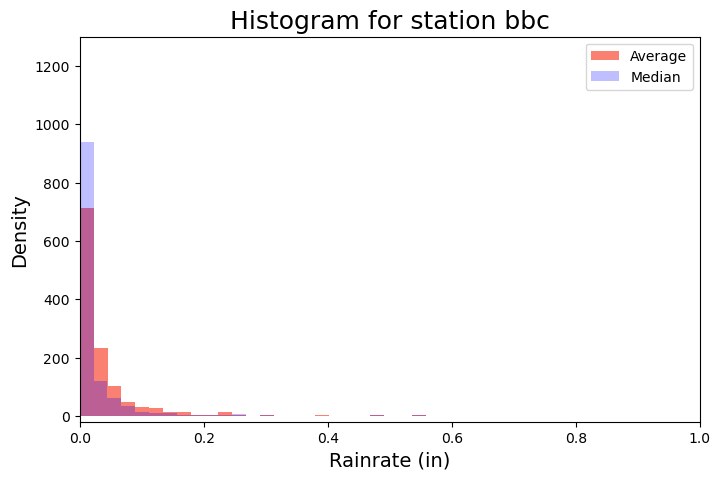

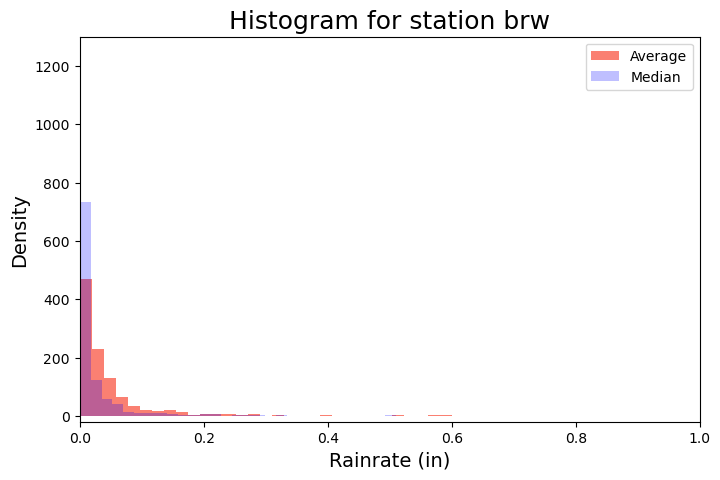

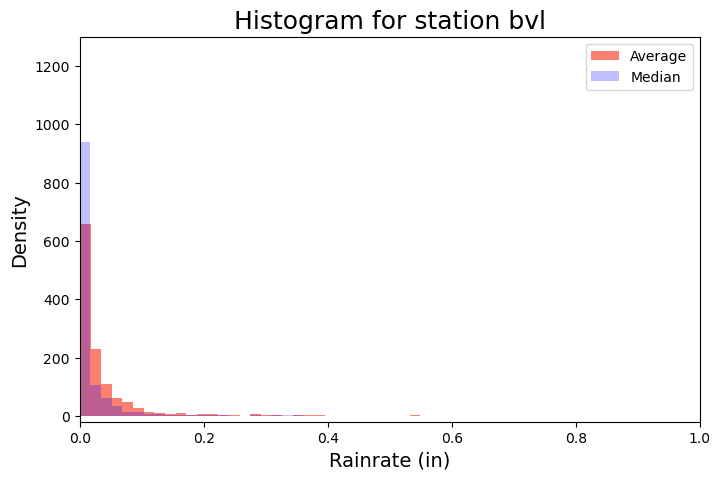

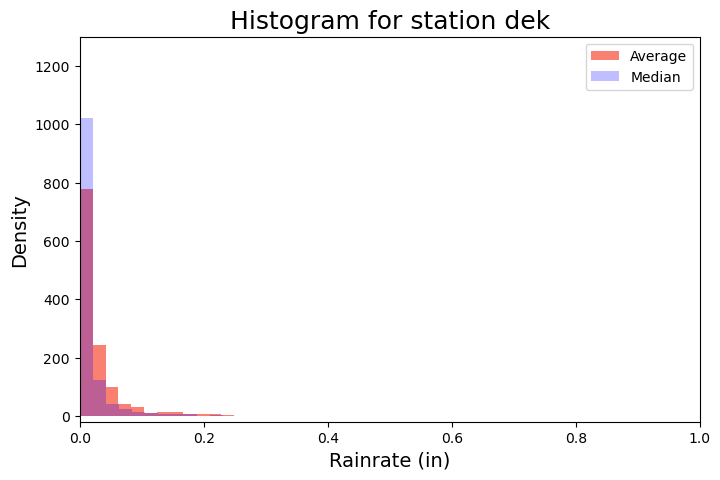

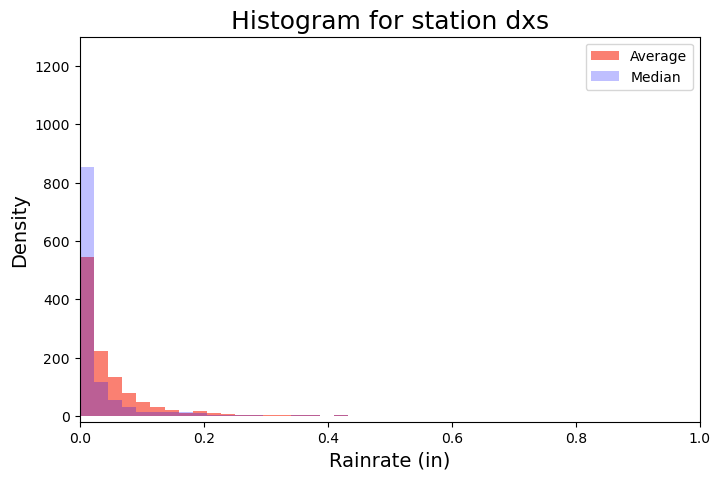

...

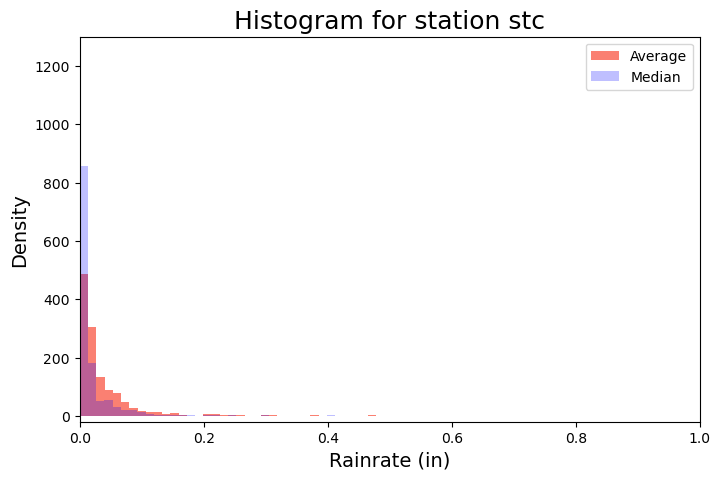

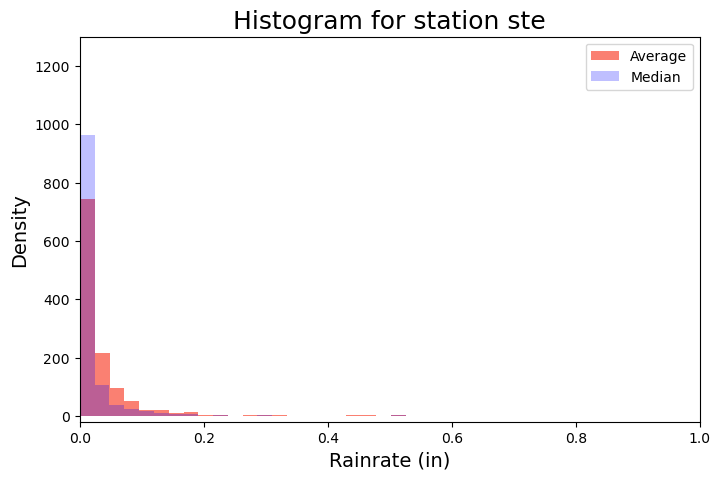

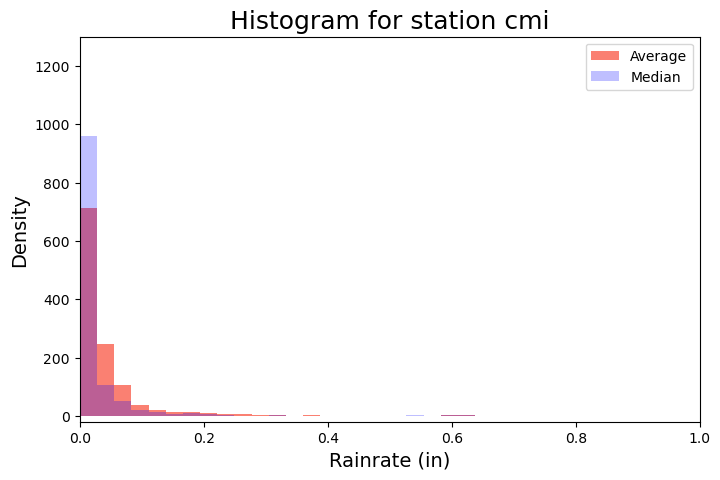

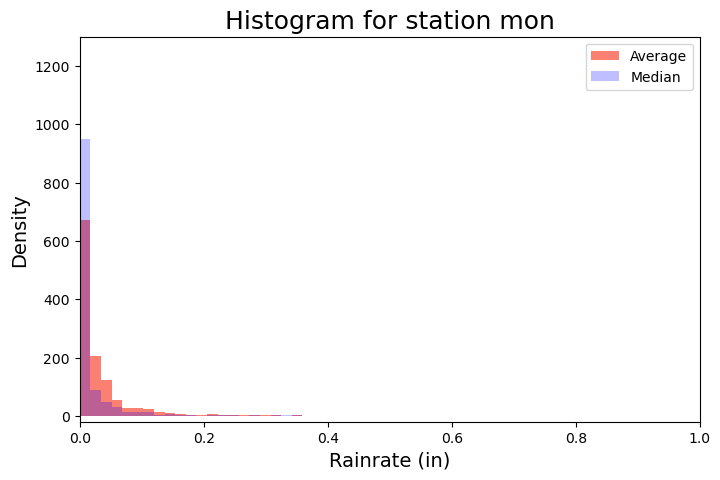

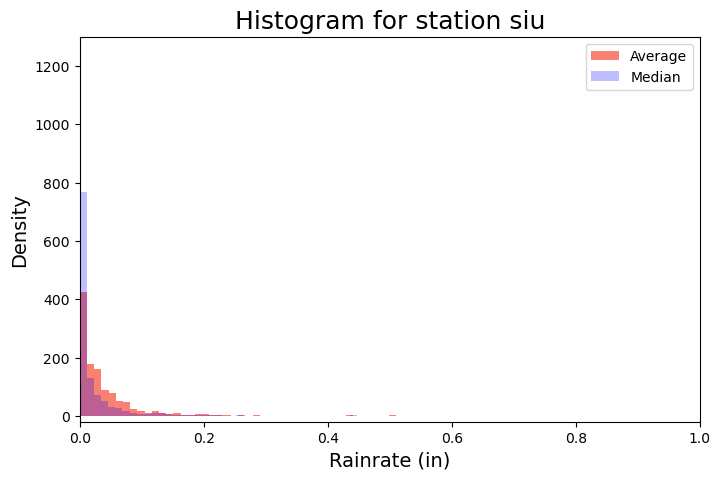

In [18]:
for s, df in station_dfs.items():
    fig, ax = plt.subplots(figsize = (8,5))
        
    station_data = station_dfs[s]
        
    ax.hist(station_data['Avg_Precipitation_rate_in'], color = 'salmon' , bins = 50, label = 'Average')
    ax.hist(station_data['Median_Precipitation_rate_in'], color = 'blue', bins = 50, alpha = 0.25, label = 'Median')
    ax.set_ylim([-20, 1300])
    ax.set_xlim([0, 1.0])
    ax.set_title('Histogram for station %s' %s, fontsize = 18)
    ax.set_xlabel('Rainrate (in)', fontsize = 14)
    ax.set_ylabel('Density', fontsize = 14)
    ax.legend()
    plt.show()

# KDE cannot handle NaN or inf, so events that have NaN sm due to impossible values need to be dropped
there are likely nan values in the other sm columns like max, sum, etc but the .max() function ignores those so only events where the prior sm=nan need to be droppped but sm = nan during a storm event could mean the sensor is erroneous for the event. For now they are kept


column 0       0.023000
1       0.010000
2       0.005207
3       0.015000
4       0.008667
          ...   
1260    0.011833
1261    0.057600
1262    0.014833
1263    0.009410
1264    0.020474
Name: Avg_Precipitation_rate_in, Length: 1224, dtype: float64
nan? 0
inf? 0
column 0       0.048
1       0.012
2       0.041
3       0.028
4       0.020
        ...  
1260    0.021
1261    0.179
1262    0.086
1263    0.094
1264    0.051
Name: Peak_Precipitation_rate_in, Length: 1224, dtype: float64
nan? 0
inf? 0
column 0       0.0180
1       0.0100
2       0.0000
3       0.0140
4       0.0080
         ...  
1260    0.0120
1261    0.0525
1262    0.0020
1263    0.0000
1264    0.0180
Name: Median_Precipitation_rate_in, Length: 1224, dtype: float64
nan? 0
inf? 0
column 0       0.092
1       0.020
2       0.302
3       0.060
4       0.104
        ...  
1260    0.071
1261    0.576
1262    0.267
1263    0.781
1264    0.389
Name: Total_Precipitation_in, Length: 1224, dtype: float64
nan? 0
inf? 0
column 

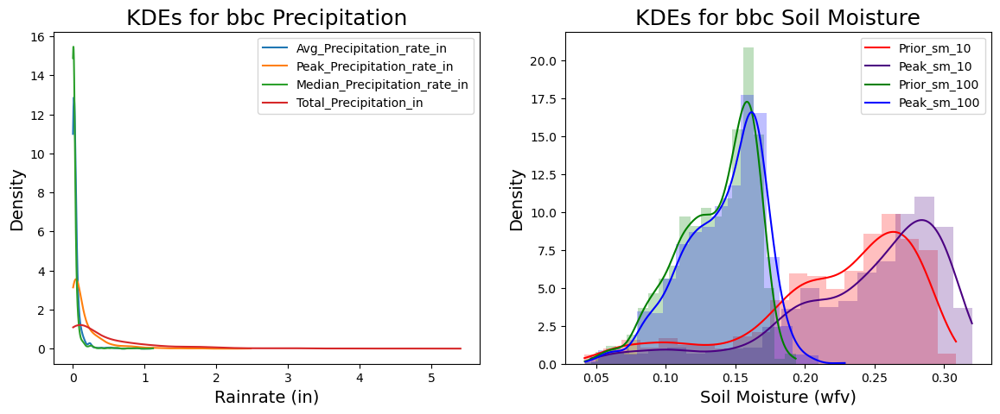

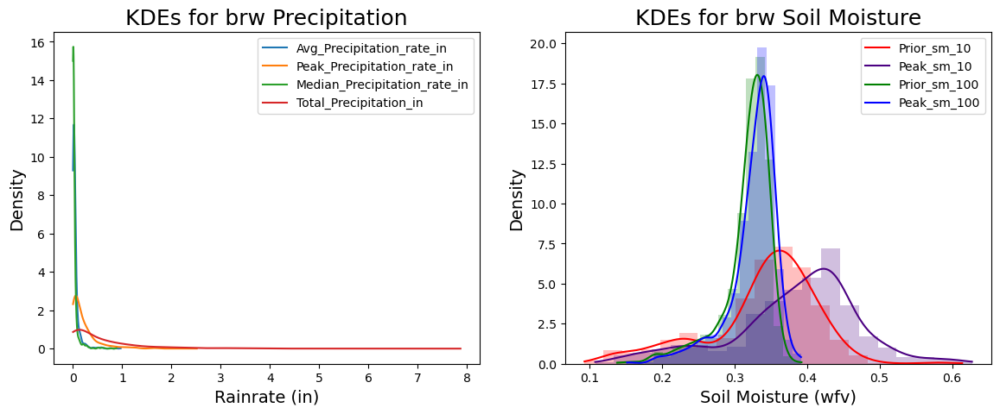

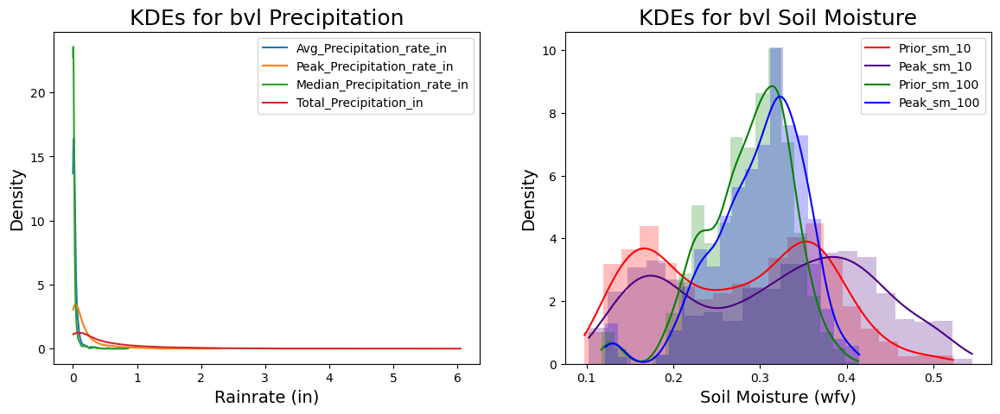

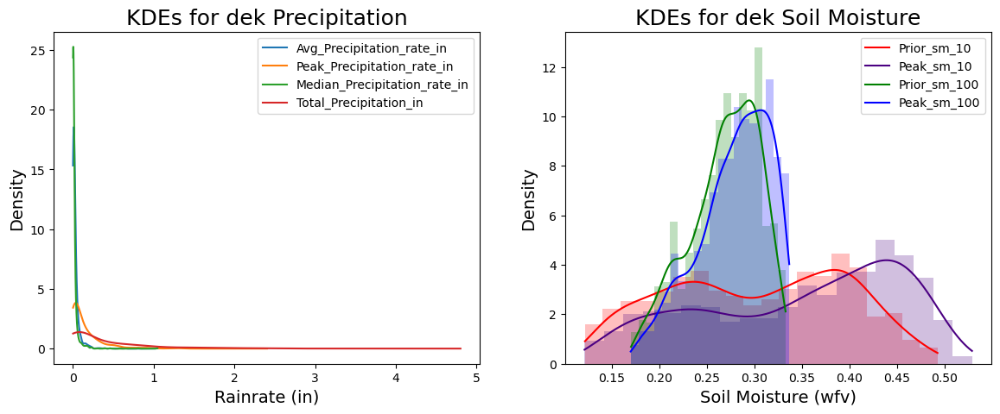

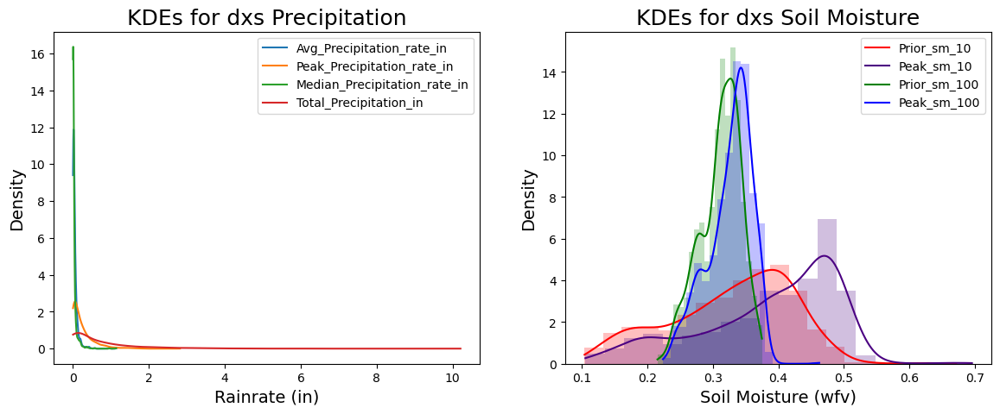

...

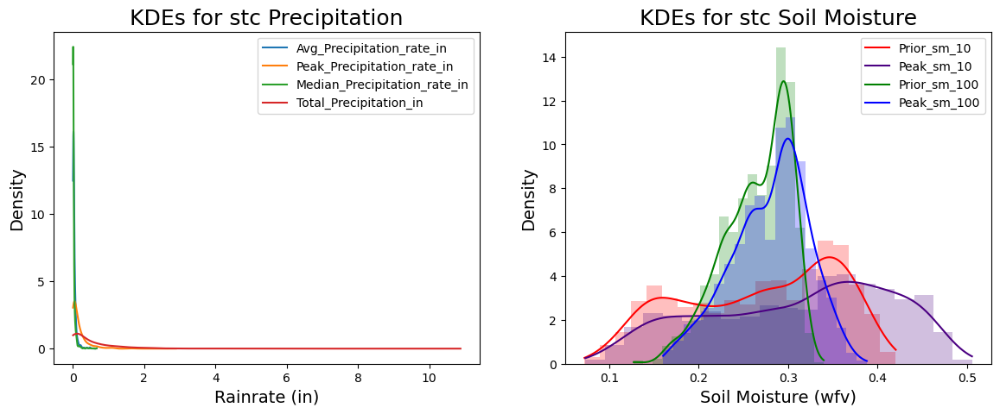

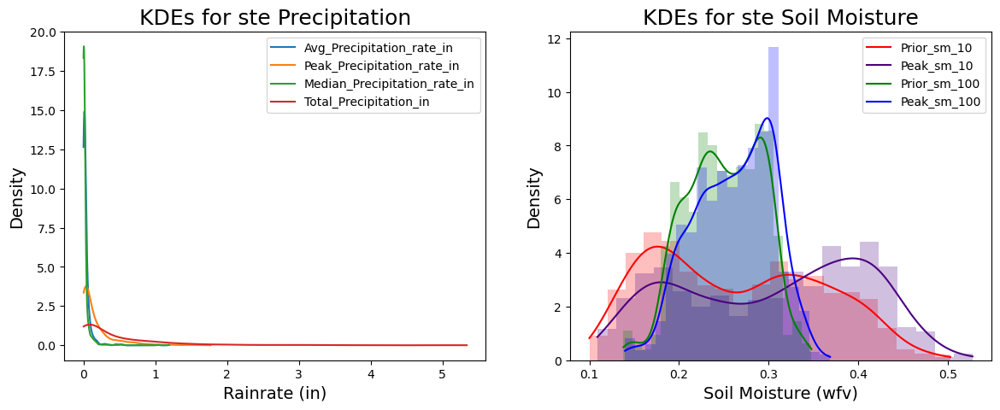

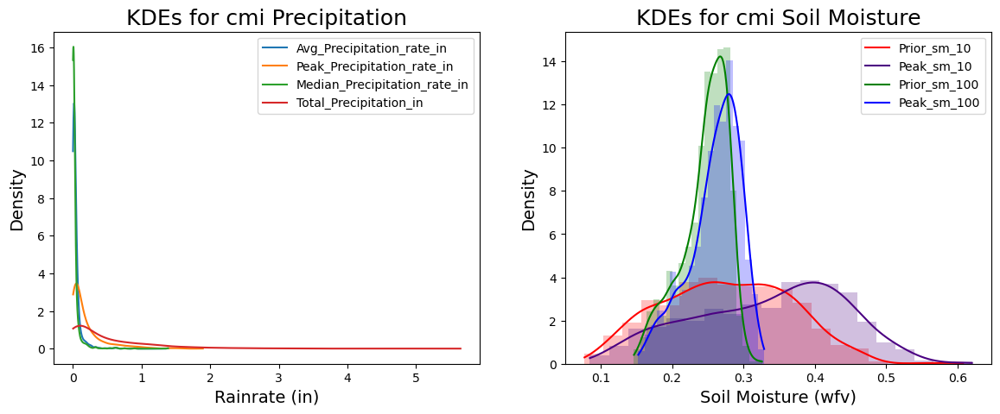

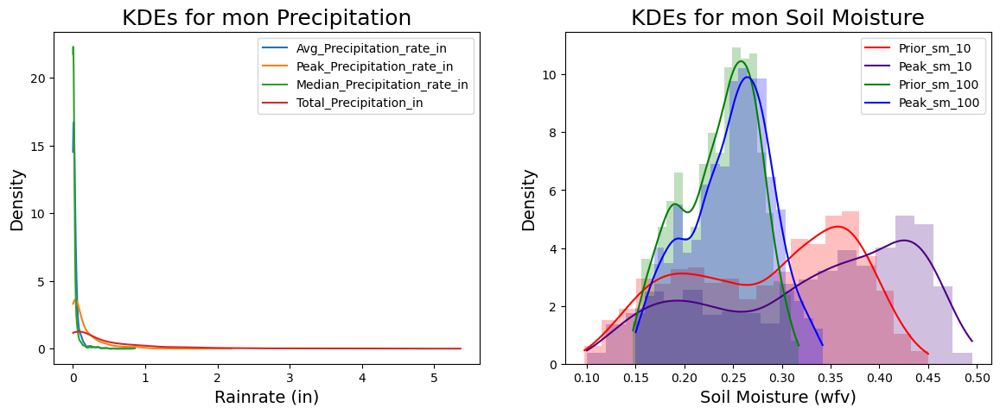

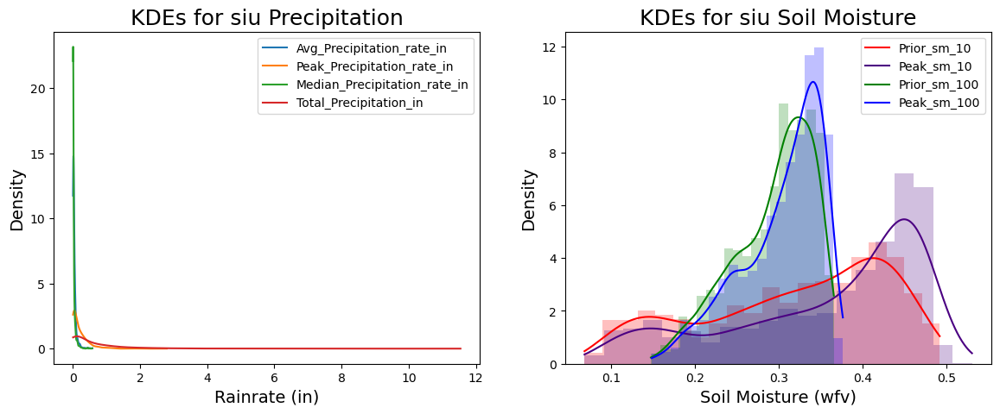

In [19]:
def pdf_generation(data):

    kde_results =[]
    for s, df in data.items():
        #s is the station key in the dictionary and df is specific dataframe 
        for col in df.columns:
            print('column', df[col])
            print('nan?',df[col].isna().sum())
            print('inf?',np.isinf(df[col]).sum())

            kde = stats.gaussian_kde(df[col], bw_method = 'scott')
            kde_results.append((s,col, kde))


    #convert results into a multiIndex df
    multi_kde_df = pd.DataFrame(kde_results, columns = ['Station', 'Column', 'KDE_Object'])
    multi_kde_df.set_index(['Station', 'Column'], inplace = True)
    print(multi_kde_df)

    #plot Kdes for each station's avg and Max P prior and max SM10 and SM100

    precip_columns_to_plot = ['Avg_Precipitation_rate_in',  'Peak_Precipitation_rate_in', 
                       'Median_Precipitation_rate_in',  'Total_Precipitation_in']
    sm_columns_to_plot = ['Prior_sm_10', 'Peak_sm_10',  'Prior_sm_100',  'Peak_sm_100']

    for s, df in data.items():
        fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize=(14,5))
        for pcol in precip_columns_to_plot:
            kde = multi_kde_df.loc[(s, pcol), 'KDE_Object']

            #create x values to apply kde object to beased on data range
            x_vals = np.linspace(df[pcol].min(), df[pcol].max(), 1000)

            #apply kde
            pdf_vals = kde(x_vals)

            ax[0].plot(x_vals, pdf_vals, label = f"{pcol}")
        ax[0].set_title(f"KDEs for {s} Precipitation", fontsize = 18)
        ax[0].set_xlabel('Rainrate (in)', fontsize = 14)
        ax[0].set_ylabel('Density', fontsize = 14)
        ax[0].legend()
        
        color_list = ['red', 'indigo','green', 'blue']
        counter = 0
        for smcol in sm_columns_to_plot:
            kde = multi_kde_df.loc[(s, smcol), 'KDE_Object']

            #create x values to apply kde object to beased on data range
            x_vals = np.linspace(df[smcol].min(), df[smcol].max(), 1000)

            #apply kde
            pdf_vals = kde(x_vals)

            ax[1].plot(x_vals, pdf_vals, color = color_list[counter], label = f"{smcol}")
            ax[1].hist(df[smcol],color = color_list[counter],density = True, bins=20, alpha =0.25)
            counter += 1
            
        ax[1].set_title(f"KDEs for {s} Soil Moisture", fontsize = 18)
        ax[1].set_xlabel('Soil Moisture (wfv)', fontsize = 14)
        ax[1].set_ylabel('Density', fontsize = 14)
        ax[1].legend()        

        plt.show()
    
    return multi_kde_df
    

multi_station_pdf = pdf_generation(station_dfs)

In [20]:
#save data and kde df
import pickle
with open(r"/data/keeling/a/cstraus2/Phd_research/KDE_pdfs_multidf.pkl", "wb") as f:
    pickle.dump(multi_station_pdf, f)

with open(r"/data/keeling/a/cstraus2/Phd_research/Station_events_data_multidf.pkl", "wb") as f:
    pickle.dump(station_dfs, f)

In [24]:
with open(r"/data/keeling/a/cstraus2/Phd_research/Station_events_data_multidf.pkl", "wb") as f:
    pickle.dump(station_dfs, f)


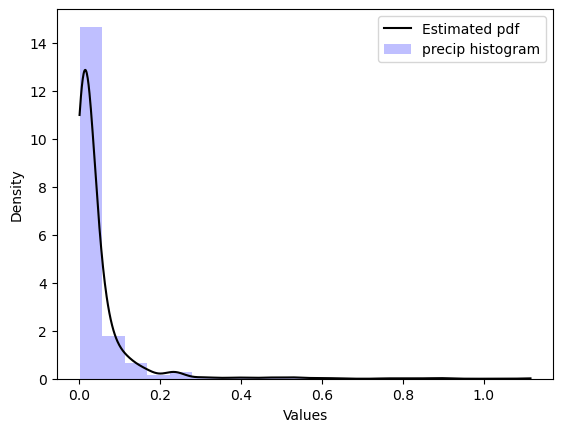

In [21]:
bbc_event_data = Event_vars_df.loc[Event_vars_df['Station'] == 'bbc']
kernels = stats.gaussian_kde(bbc_event_data['Avg_Precipitation_rate_in'], bw_method = 'scott') #creating a KDE object
#create a range of x values in an array to evaluate the kde 
x_values = np.linspace(min(bbc_event_data['Avg_Precipitation_rate_in']), 
                       max(bbc_event_data['Avg_Precipitation_rate_in']),1000)
#apply the object at the points
pdf_vals = kernels(x_values)

fig3, ax3 = plt.subplots()
ax3.plot(x_values, pdf_vals, label ='Estimated pdf', color = 'black')
ax3.hist(bbc_event_data['Avg_Precipitation_rate_in'],density = True, bins=20, alpha =0.25, 
         color ='blue', label = 'precip histogram')
ax3.set_xlabel('Values')
ax3.set_ylabel('Density')

ax3.legend()


calculate shannon's entropy and then the mutual information

shannon's entropy, H(X) = sum(p(x_i)*log(1/p(x_i))) = -sum(p(x_i)*log(p(x_i)))

mutual information, I(x,y) = H(x) - H(x|y) or H(y) - H(y|x)